# Galois Theory: On Formulas for Solving Fifth-Degree Equations

Run the example code cells in order. All ten figures are embedded. Core calculations use Python's standard library; the separately labelled symbolic check requires SymPy. Each browser activity has a link beside its explanation. Complete the coding starter, then uncomment its test call. The reference solution uses a different name, so Run All does not overwrite the editable starter.

[Read in Korean](https://pilkwangkim.github.io/posts/Galois-Theory-From-Scratch-KR/) · [Permutation-group Python code](https://pilkwangkim.github.io/assets/code/galois-reference.py)

For $ax^2+bx+c=0$ with $a\ne0$, the quadratic formula is familiar:

$$
x=\frac{-b\pm\sqrt{b^2-4ac}}{2a}.
\tag{1}
$$

The square-root term $\sqrt{b^2-4ac}$ is a **radical**. The same name covers cube-root expressions such as $\sqrt[3]2$ and, more generally, roots of any positive integer order. A **radical expression** combines arithmetic with finitely many such root extractions. Examples include $1+\sqrt2$ and the nested expression $\sqrt{2+\sqrt3}$.

Cubic and quartic equations also have formulas involving arithmetic and radicals. For degree five, something changes. It is not merely that the corresponding expression becomes too long: some quintics have roots that no finite expression of that kind can represent.

Yet their roots exist, and a computer can approximate them. The difference is between **finding a number to a chosen accuracy** and **expressing that number using a prescribed collection of exact operations**.

The answer depends on **which exchanges of the roots preserve their arithmetic relationships**. For $x^2-2=0$, exchanging $\sqrt2$ and $-\sqrt2$ preserves each root's square $2$, their sum $0$, and their product $-2$. In general, every addition-and-multiplication relation determined by the coefficients must survive, not just one selected equation. The allowed transformations form the **Galois group**. The structure obtained by composing these transformations determines whether the roots can be expressed using arithmetic and radicals.

## 1. What counts as a formula for a root?

First specify which numbers are available for arithmetic. A **field** is a collection containing $0$ and $1$ in which addition, subtraction, multiplication, and division by a nonzero number stay within the collection and obey the usual arithmetic rules. The rational numbers form a field: for example, $1/2+1/3=5/6$ is still rational. The field available at the start is the **base field** $F$; for equations with rational coefficients, the usual choice is $F=\mathbb Q$, the field of all rational numbers.

A **polynomial** is a finite sum of nonnegative integer powers of a variable, each multiplied by a coefficient. For example, $3x^2-2x+1$ has coefficients $3,-2,1$ and **degree** $2$, the largest power with a nonzero coefficient. A **radical expression over $F$** uses finitely many of the following operations:

- Choose a number already in $F$.
- Add, subtract, multiply, or divide previously constructed numbers, with a nonzero denominator.
- Choose an $m$-th root of a previously constructed number $a$: a number $b$ satisfying $b^m=a$, where $m$ is a positive integer. For instance, $\sqrt2$ is one square-root choice for $a=2$.

Intermediate numbers may be complex. Nested radicals are allowed. The number of operations must be finite. Allowing an arbitrary new constant equal to the desired answer would change the problem, so the base field must remain explicit.

For example,

$$
\begin{gathered}
\sqrt{2+\sqrt3}\\
\text{and}\\
\sqrt[3]{\frac{1+\sqrt5}{2}}
\end{gathered}
\tag{2}
$$

are radical expressions over $\mathbb Q$. A decimal such as $1.4405003973$ is rational, but it is only an approximation to a particular irrational root. An infinite convergent sequence of rational approximations is not one finite radical expression.

A polynomial is **solvable by radicals over $F$** when all its roots can be obtained this way. The **Abel–Ruffini theorem** rules out a radical formula that works for every **quintic**, meaning a degree-$5$ polynomial. It does not rule out formulas for particular quintics, numerical algorithms, convergent series, or expressions that allow other kinds of functions as additional operations. For instance, $x^5-2=0$ is solvable by radicals.

The important step is admitting a number that was not available before. Starting with rational numbers, $\sqrt3$ is new; once it is admitted, ordinary arithmetic also gives $2+\sqrt3$ and $1/(2+\sqrt3)=2-\sqrt3$. Admitting $\sqrt{2+\sqrt3}$ may enlarge the available numbers again. A field extension records exactly what becomes available after each such step, including all the consequences of ordinary arithmetic.


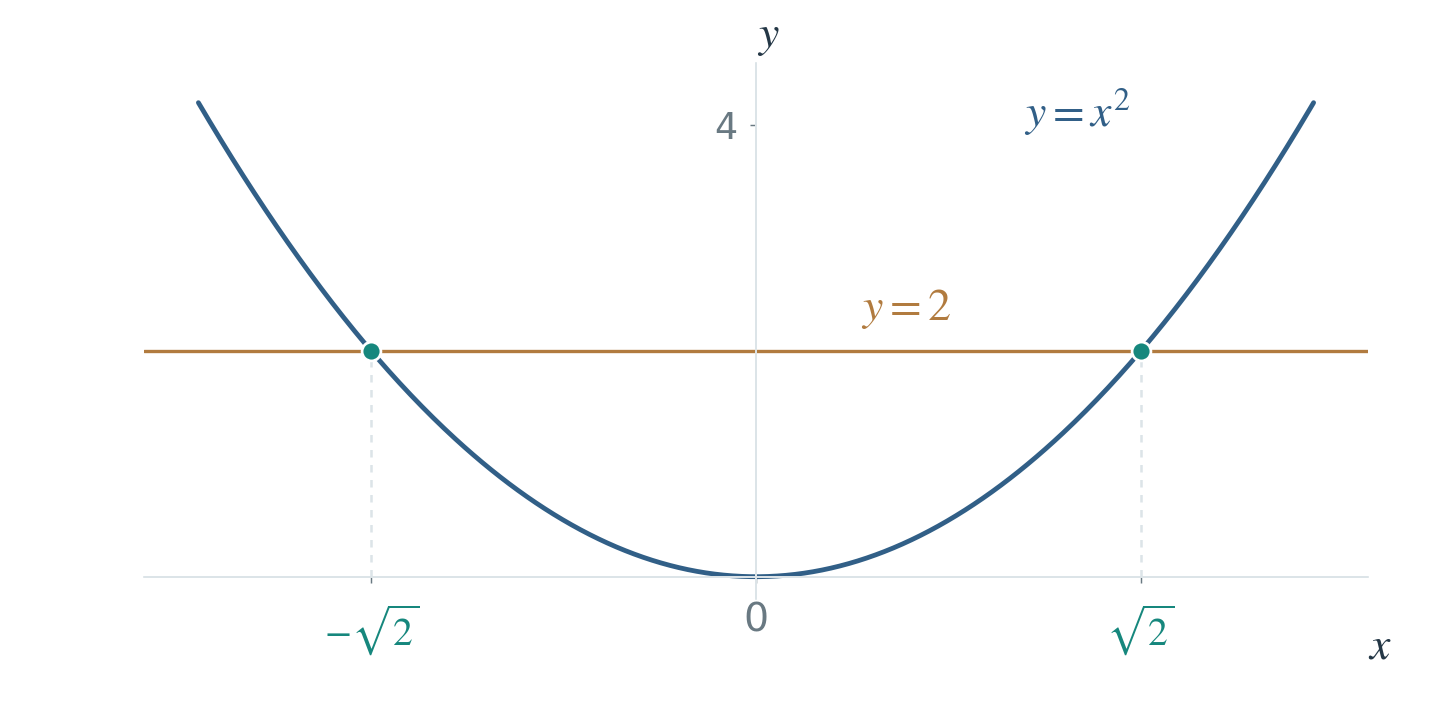

*Figure 1. Squaring sends both $-\sqrt2$ and $\sqrt2$ to $2$. The intersections of $y=x^2$ with $y=2$ make the two square-root choices visible.*

## 2. A field extension is a vector space with multiplication

$\mathbb Q$, $\mathbb R$, and $\mathbb C$ are fields: they contain the rational, real, and complex numbers, respectively. The integers are not a field: dividing $1$ by $2$ leaves the integers.

A **subfield** is a smaller field contained in another field, using the same arithmetic. For example, $\mathbb Q$ is a subfield of $\mathbb R$. A **field extension** $K/F$ describes exactly this relationship: $F\subseteq K$, with $F$ a subfield of $K$. The slash is not a division sign. Since elements of $F$ can multiply elements of $K$, the larger field is also a vector space over the smaller one.

Here the choice of **scalar field** matters. In a vector space over $\mathbb Q$, the coefficients of a linear combination must be rational, even when the vectors themselves are irrational numbers. Thus the numbers $1$ and $\sqrt2$ can serve as two distinct basis vectors. The relation $(-\sqrt2)\cdot1+1\cdot\sqrt2=0$ is not a rational linear relation: its first coefficient is not in $\mathbb Q$.

The notation $F(\alpha)$ means the smallest field containing $F$ and a number $\alpha$. It includes everything obtainable from them by arithmetic, not just $F$ together with that one extra element. Adding the number this way is called **adjoining** it. Take $\alpha=\sqrt2$. In this case,

$$
\mathbb Q(\alpha)
=\{a+b\alpha:a,b\in\mathbb Q\}.
\tag{3}
$$

Why are two coordinates enough? Powers reduce using $\alpha^2=2$: for example, $\alpha^3=2\alpha$ and $\alpha^4=4$. Products therefore return to the same form. A nonzero number's **multiplicative inverse** is its reciprocal, the number that multiplies it to $1$. For a concrete division, $(3+2\alpha)(3-2\alpha)=9-8=1$, so the inverse of $3+2\alpha$ is already present too.


#### Check closure under arithmetic, including division


Being **closed** under an operation means that applying it to elements of a set gives another element of the same set. Write $u=a+b\alpha$ and $v=c+d\alpha$. Then

$$
\begin{aligned}
u+v&=(a+c)+(b+d)\alpha,\\
uv&=(ac+2bd)\\
  &\quad+(ad+bc)\alpha.
\end{aligned}
\tag{4}
$$

Division does not require a new kind of number either:

$$
\begin{gathered}
\frac1{a+b\alpha}
=\frac{a-b\alpha}{a^2-2b^2},\\
a+b\alpha\ne0.
\end{gathered}
\tag{5}
$$

The denominator cannot vanish for rational $a,b$ unless both are zero: otherwise $a/b$ would be a rational square root of $2$. Thus the set in (3) is closed under the required operations.



The vectors $1,\alpha$ are linearly independent over $\mathbb Q$. If $a+b\alpha=0$ with $b\ne0$, then $\alpha=-a/b$ would be rational. Consequently,

$$
[\mathbb Q(\sqrt2):\mathbb Q]=2.
\tag{6}
$$

The brackets denote **extension degree**, meaning vector-space dimension over the specified base field. An extension with finite dimension is called a **finite extension**. This does not mean that it contains finitely many numbers: $\mathbb Q(\sqrt2)$ has infinitely many elements but only two basis directions over $\mathbb Q$. An extension of degree $2$ is called **quadratic**; $\mathbb Q(\sqrt2)$ is therefore a quadratic field over $\mathbb Q$.

If we instead allow scalars from $\mathbb Q(\sqrt2)$ itself, the single vector $1$ is a basis: every element is a scalar times $1$. The same set can have dimension $2$ over one field and dimension $1$ over another.

Multiplication by $\alpha$ is a $\mathbb Q$-linear map. Its first matrix column comes from $\alpha\cdot1=\alpha$, with coordinates $(0,1)$; its second comes from $\alpha\cdot\alpha=2$, with coordinates $(2,0)$. In the ordered basis $(1,\alpha)$, this gives

$$
\begin{gathered}
M_\alpha=\begin{pmatrix}0&2\\1&0\end{pmatrix},\\
M_\alpha\binom ab=\binom{2b}a,\\
M_\alpha^2=2I.
\end{gathered}
\tag{7}
$$

The matrix acts on rational coordinate vectors. Its eigenvalues $\pm\sqrt2$ appear only after extending the scalar field. A rational matrix need not have rational eigenvalues.

A different map replaces $\alpha$ with $-\alpha$: it sends $3+2\alpha$ to $3-2\alpha$ while leaving every rational number unchanged. This is **algebraic conjugation**; write it as $\sigma(a+b\alpha)=a-b\alpha$. It is not ordinary **complex conjugation**, which sends $a+bi$ to $a-bi$ for real $a,b$, where $i^2=-1$, and therefore fixes both of these real numbers. The sign change preserves products because $(-\alpha)^2=2$ satisfies the same defining relation. In coordinates it is $(a,b)\mapsto(a,-b)$, not multiplication by $\alpha$.


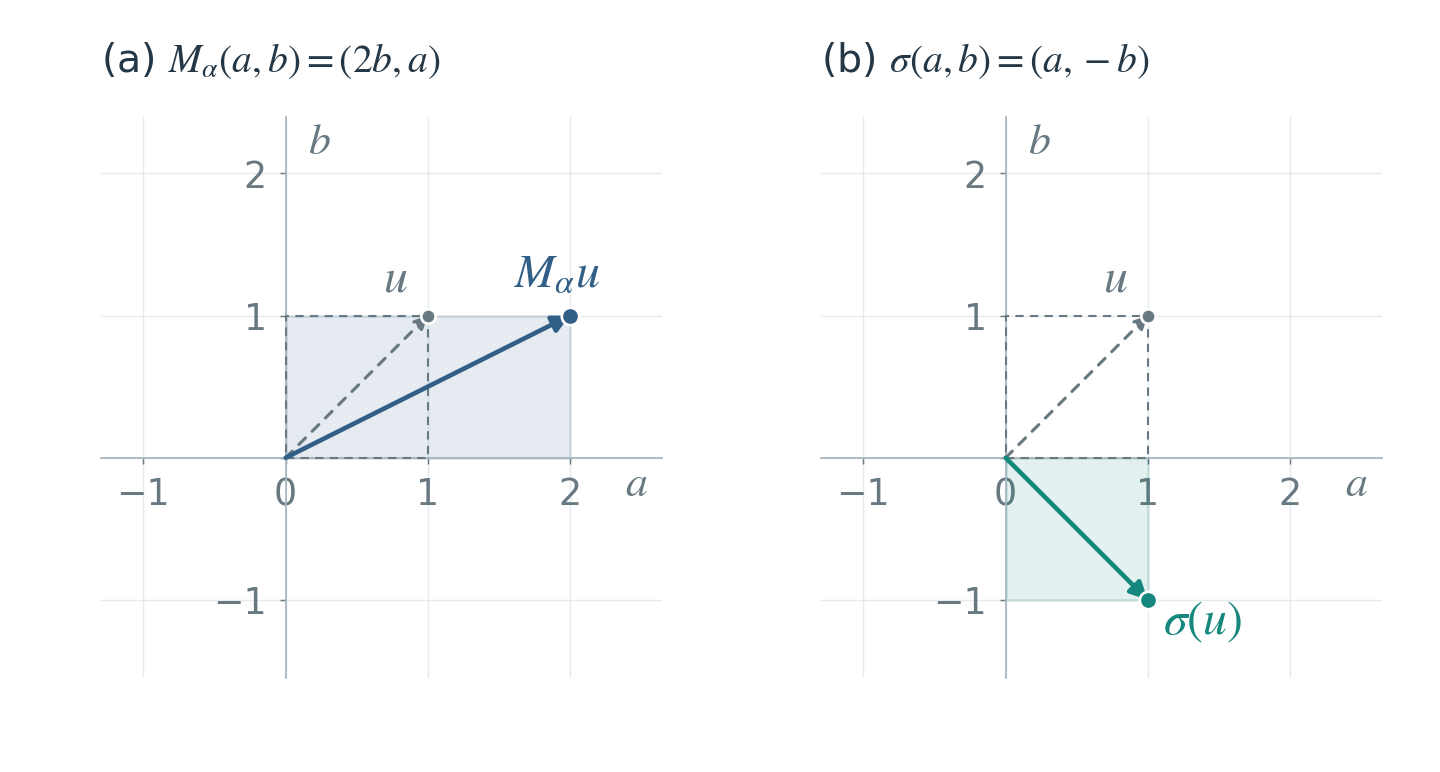

*Figure 2. In the basis $(1,\alpha)$ over $\mathbb Q$, $\alpha=\sqrt2$, the dashed unit square and $u=(1,1)$ map to the shaded regions and colored vectors. Multiplication gives $M_{\alpha}u=(2,1)$; algebraic conjugation gives $\sigma u=(1,-1)$. These are coefficient coordinates, not Re/Im coordinates.*

Multiplying a number by its conjugate removes the square-root term. In this quadratic field, that product is called the **field norm**: $N(a+b\sqrt2)=a^2-2b^2$. For instance, $N(1+\sqrt2)=(1+\sqrt2)(1-\sqrt2)=-1$. Despite its name, this norm is not a length and can be negative. Formula (5) divides the conjugate by this rational number to obtain the inverse.


#### Python: exact arithmetic and algebraic conjugation in rational coordinates


The following representation keeps every coefficient exact. A pair $(a,b)$ means $a+b\sqrt2$. The term $2bd$ in `qmul` replaces $bd(\sqrt2)^2$, `qconj` changes the sign of the second coordinate, and `qinv` implements (5). The last assertion checks that conjugation preserves multiplication.


In [1]:
from fractions import Fraction

def qadd(u, v):
    return tuple(Fraction(a) + Fraction(b) for a, b in zip(u, v))

def qmul(u, v):
    a, b = map(Fraction, u)
    c, d = map(Fraction, v)
    # Reduce sqrt(2)**2 to the rational number 2.
    return a*c + 2*b*d, a*d + b*c

def qconj(u):
    a, b = map(Fraction, u)
    return a, -b

def qinv(u):
    a, b = map(Fraction, u)
    norm = a*a - 2*b*b
    if norm == 0:
        raise ZeroDivisionError("Zero has no multiplicative inverse")
    return a/norm, -b/norm

assert qmul((1, 1), (1, -1)) == (-1, 0)
assert qmul((3, 2), qinv((3, 2))) == (1, 0)
assert qconj(qmul((1, 2), (3, 4))) == qmul(qconj((1, 2)), qconj((3, 4)))
print("Exact arithmetic in Q(sqrt(2)): passed")


Exact arithmetic in Q(sqrt(2)): passed


**Exact arithmetic in Q(√2):** [Open the browser activity](https://pilkwangkim.github.io/posts/Galois-Theory-From-Scratch/#lab-galois-quadratic).


Change the two coefficient pairs and compare their product with the conjugate product. Conjugation reverses the $\sqrt2$ coordinate, but it also preserves multiplication. A general invertible matrix does not have that property.

## 3. Minimal polynomials explain extension degree

For $\alpha=\sqrt2$, the successive powers begin $1,\alpha,2,2\alpha,4,\ldots$. The first two are independent over $\mathbb Q$, but the third satisfies $\alpha^2-2\cdot1=0$. This first dependence explains why two coordinates suffice. Although $\alpha^4-4=0$ also holds, that later relation does not require a four-dimensional space.

An element $\alpha$ is **algebraic over $F$** if it satisfies a nonzero polynomial with coefficients in $F$; $\sqrt2$ is algebraic over $\mathbb Q$ because it satisfies $x^2-2=0$. Write $F[x]$ for the set of all polynomials with coefficients in $F$. A polynomial equation is a linear dependence among $1,\alpha,\alpha^2,\ldots$.

A polynomial is **monic** when its leading coefficient—the coefficient of its highest power—is $1$. Dividing $2x^2-4$ by its leading coefficient gives the monic polynomial $x^2-2$. Among the polynomials that become zero at $\alpha$, there is a unique monic one of smallest degree, its **minimal polynomial** $m_\alpha(x)$. For $\alpha=\sqrt2$, this is $x^2-2$, not $x^4-4$: the latter also vanishes at $\alpha$, but has higher degree.

A positive-degree polynomial is **irreducible over $F$** if it cannot be written as a product of two positive-degree polynomials in $F[x]$; if it can, it is **reducible**. The field matters: $x^2-2$ is irreducible over $\mathbb Q$, but factors as $(x-\sqrt2)(x+\sqrt2)$ over $\mathbb Q(\sqrt2)$. A minimal polynomial is irreducible: otherwise a smaller factor would already vanish at $\alpha$.

If $\deg m_\alpha=d$, then

$$
\begin{gathered}
\text{Basis of }F(\alpha)/F:\\
1,\alpha,\ldots,\alpha^{d-1},\\
[F(\alpha):F]=d.
\end{gathered}
\tag{8}
$$

The degree is the number of independent powers before the first dependence. **Polynomial division** subtracts suitable multiples of a divisor until the remainder has smaller degree than the divisor. For example, $x^3=x(x^2-2)+2x$. At $x=\alpha=\sqrt2$, the multiple of $x^2-2$ vanishes, leaving $\alpha^3=2\alpha$. Dividing by $m_\alpha$ in the same way reduces every higher power to the $d$ basis directions in (8).

Even inverses can be expressed in those coordinates. For example, $(\alpha+1)^{-1}=\alpha-1$ when $\alpha=\sqrt2$, since $(\alpha+1)(\alpha-1)=1$.


#### Why the first independent powers also handle every rational expression


Polynomial division by $m_\alpha$ reduces all higher powers to a linear combination of these $d$ powers. If a nonzero combination of the proposed basis vectors vanished, it would give a polynomial of degree below $d$ vanishing at $\alpha$, contradicting minimality. Irreducibility follows from the same minimality: if $m_\alpha=uv$ with both factors of smaller positive degree, then $u(\alpha)v(\alpha)=0$ in a field, so one factor must already vanish.

Here a **rational expression** means a quotient of polynomial expressions, such as $1/(\alpha+1)$; its value need not be a rational number. To handle any such quotient, it is enough to express $1/q(\alpha)$ in the same basis whenever $q(\alpha)\ne0$.

Two polynomials are **relatively prime** when they have no common factor of positive degree. Irreducibility makes $q$ and $m_\alpha$ relatively prime: the only possible nonconstant common factor would be $m_\alpha$ itself, and that would force $q(\alpha)=0$.

The **polynomial Euclidean algorithm** repeatedly divides with remainder: divide the first polynomial by the second, then the second by the remainder, and continue until the remainder is zero. Degrees decrease, so the process stops. Its last nonzero remainder is a common divisor of largest degree; for relatively prime polynomials it is a nonzero constant. Substituting the successive remainder equations backward, and dividing by that constant, gives polynomials $u,v\in F[x]$ with $u q+v m_\alpha=1$. Evaluating at $\alpha$ gives $u(\alpha)q(\alpha)=1$, so $q(\alpha)^{-1}=u(\alpha)$. No additional coordinates are needed for inverses.

For a concrete instance, dividing $x^2-2$ by $x+1$ gives $x^2-2=(x-1)(x+1)-1$. Rearranging this one remainder equation gives $(x-1)(x+1)-(x^2-2)=1$. Setting $x=\sqrt2$ removes the last term and gives the inverse of $\sqrt2+1$ directly.



For $\sqrt[3]2$, the minimal polynomial is $x^3-2$. A reducible **cubic**, meaning a degree-$3$ polynomial, over $\mathbb Q$ would have a linear factor and therefore a rational root. The **rational-root test** restricts the possible rational roots using the coefficients; here the only candidates are $1,-1,2,-2$, and none works. Thus $x^3-2$ is irreducible, and the real field $\mathbb Q(\sqrt[3]2)$ has basis $(1,\sqrt[3]2,\sqrt[3]4)$ and degree $3$.


#### Check the cubic example without assuming irreducibility


Suppose a rational root is $p/q$, where $p,q$ are integers, $q>0$, and they have no common prime factor. Substitution gives $p^3=2q^3$. Every prime dividing $q$ would then also divide $p$, a contradiction, so $q=1$. Now $p^3=2$ implies that $p$ divides $2$. This is the rational-root test for this monic polynomial: any rational root must be an integer dividing the constant term.

The candidates $1,-1,2,-2$ give values $-1,-3,6,-10$, respectively, so none is a root. A factorization of a cubic into positive-degree factors must include a linear factor. No rational root therefore means no factorization over $\mathbb Q$.



### Dimensions multiply along a tower

Take $E=\mathbb Q(\sqrt2)$ and then $K=E(i)=\mathbb Q(\sqrt2,i)$. The first step has basis $(1,\sqrt2)$. All elements of $E$ are real, so $i$ is not already in $E$; adjoining it gives basis $(1,i)$ over $E$. An element of $K$ is $x+yi$ with $x,y\in E$. Substituting $x=a+b\sqrt2$ and $y=c+d\sqrt2$ gives $a+b\sqrt2+ci+d\,i\sqrt2$. Thus the two two-coordinate descriptions combine into four rational coordinates, with basis $(1,\sqrt2,i,i\sqrt2)$.

A chain of nested fields such as $F\subseteq E\subseteq K$ is called a **tower**. When both steps have finite extension degree, the same expansion gives the **tower law**:

$$
[K:F]=[K:E]\,[E:F].
\tag{9}
$$

In the example, $[K:\mathbb Q]=2\cdot2=4$. The multiplication counts basis directions, not the number of radical symbols in an expression.


#### Why products of basis vectors form a basis of the whole tower


Suppose $e_1,\ldots,e_r$ is a basis for $E/F$ and $u_1,\ldots,u_s$ is a basis for $K/E$. Expand an element of $K$ first as $\sum_j c_j u_j$ with $c_j\in E$, then expand each $c_j=\sum_i a_{ij}e_i$ with $a_{ij}\in F$. This proves that the $rs$ products $e_i u_j$ span $K$ over $F$.

If $\sum_{i,j}a_{ij}e_i u_j=0$, independence of the $u_j$ over $E$ gives $\sum_i a_{ij}e_i=0$ for each $j$. Independence of the $e_i$ over $F$ then gives every $a_{ij}=0$. So the product vectors are also independent. In the concrete example, this is why none of $1,\sqrt2,i,i\sqrt2$ is a rational linear combination of the others.



## 4. One root is not necessarily enough: splitting fields

Allowing complex numbers, a degree-$n$ polynomial has $n$ roots when each repeated root is counted as often as its factor occurs. This is a statement about the existence and number of roots, not a promise that radicals can express them.

For $x^2-2$, adjoining $\sqrt2$ also gives $-\sqrt2$. For $x^3-2$, adjoining its real root $\alpha=\sqrt[3]2$ does not give the other roots:

$$
\begin{gathered}
\alpha,\quad\alpha\omega,\quad\alpha\omega^2,\\
\omega=\frac{-1+i\sqrt3}{2},\\
\omega^3=1,\qquad\omega\ne1.
\end{gathered}
\tag{10}
$$

An **$m$-th root of unity** is a number $z$ satisfying $z^m=1$. A **primitive** root $\zeta_m$ has $m$ distinct powers $1,\zeta_m,\ldots,\zeta_m^{m-1}$, giving all the roots of that equation. The number $\omega$ above is a primitive cube root of unity.

For example, the fourth roots of unity are $1,i,-1,-i$. The powers of $i$ produce all four, so $i$ is primitive. The number $-1$ also satisfies $(-1)^4=1$, but its powers only alternate between $1$ and $-1$, so it is not primitive. Multiplying a root by these factors gives the different possible choices of a radical: if $\beta^m=a$ with $a\ne0$, then the $m$ roots are $\beta\zeta_m^k$, for $k=0,\ldots,m-1$.


#### Roots of unity as equally spaced points on a circle


The **complex plane** represents $a+bi$ by the point $(a,b)$. The fourth roots $1,i,-1,-i$ are the four points $(1,0),(0,1),(-1,0),(0,-1)$. Multiplying by $i$ rotates each point a quarter turn, so four multiplications return to $1$.

More generally, $e^{i\theta}$ denotes the point $\cos\theta+i\sin\theta$ on the unit circle. Multiplication adds the angles, as follows from the sine and cosine addition formulas. Choosing $\zeta_m=e^{2\pi i/m}$ gives a rotation by $1/m$ of a full turn. Its first $m$ powers visit $m$ distinct, equally spaced points and the next returns to $1$. For $m=3$, this gives $\omega=-1/2+i\sqrt3/2$, the number in (10).



Every element of $\mathbb Q(\alpha)$ is real, but the last two roots are nonreal. The **splitting field** is the smallest field containing the base field and every root. Here it is

$$
L=\mathbb Q(\alpha,\omega).
\tag{11}
$$

The first step has degree $3$. The second has degree $2$: $\omega$ satisfies $x^2+x+1=0$ and is not in the real field $\mathbb Q(\alpha)$. Thus $[L:\mathbb Q]=6$.

The difference between the quadratic and cubic examples concerns **normality**. An extension is **normal** if every irreducible polynomial over the base field that has one root in the extension has all its roots there. The requirement concerns all such polynomials, not just a single chosen equation. In $\mathbb Q(\sqrt2)$, every irrational element $a+b\sqrt2$ has minimal polynomial $(x-a)^2-2b^2$; its other root $a-b\sqrt2$ is in the same field. Rational elements have degree-$1$ minimal polynomials, so they have no missing partner either. This extension is therefore normal. In the cubic example, $x^3-2$ itself witnesses the failure: it has a root in $\mathbb Q(\sqrt[3]2)$ but its other two roots are missing.

A **repeated root** is a root appearing more than once as a factor: for example, $(x-1)^2$ has the root $1$ twice. An extension is **separable** if each element's minimal polynomial has no repeated roots. A finite extension that is both normal and separable is a **Galois extension**. Over $\mathbb Q$, separability is automatic: for example, the minimal polynomials $x^2-2$ and $x^3-2$ have distinct roots. The reason is that $\mathbb Q$ has **characteristic zero**: repeatedly adding $1$ never gives $0$. The derivative argument below proves why this property excludes repeated roots in irreducible polynomials. Thus the splitting fields above are Galois extensions; the normality condition is why collecting all roots matters.


#### Precise definitions of normal and separable, and why separability holds over Q


An **algebraic extension** is an extension in which every element is algebraic over the base field. Every finite extension has this property: in a finite-dimensional vector space, the powers $1,\alpha,\alpha^2,\ldots$ must eventually be linearly dependent. The two conditions are:

- A finite algebraic extension $L/F$ is **normal** if every irreducible polynomial over $F$ having one root in $L$ splits completely in $L$.
- It is **separable** if the minimal polynomial of each element has no repeated roots.

A finite extension satisfying both is a **Galois extension**. A field has **characteristic zero** when adding $1$ to itself any positive number of times never gives $0$. In $\mathbb Q$, these sums are the ordinary positive integers, so its characteristic is zero. Over any such field, all irreducible polynomials are separable.

This can be checked using the **polynomial derivative**, obtained term by term from the rule $x^k\mapsto kx^{k-1}$, with constants sent to zero. For an irreducible polynomial of positive degree in characteristic zero, its derivative is nonzero and has smaller degree. Irreducibility prevents the two from having a common factor of positive degree. But a repeated factor $(x-r)^2$ would leave a factor $x-r$ in the derivative as well. The minimal polynomial of their common root would then divide both polynomials, contradicting the absence of a common factor. Repeated roots are therefore excluded.

For example, $x^2-2$ and its derivative $2x$ have no common root: a common root would have to be both $0$ and a square root of $2$. The polynomial $(x^2-2)^2$ does have repeated roots, but the minimal polynomial of $\sqrt2$ is still $x^2-2$. Separability concerns the minimal polynomial, not whether someone chose to square an equation.



A splitting field of a polynomial over $\mathbb Q$ is a finite Galois extension. If the polynomial itself has repeated factors, use its distinct irreducible factors; its splitting field is unchanged.


## 5. Automorphisms preserve arithmetic, not just a list of roots

A **bijection** is a function that reaches every output exactly once: it neither merges two inputs nor misses any output, so it can be reversed. Conjugation in $\mathbb Q(\sqrt2)$ is an example, since applying the same sign change again undoes it.

An **$F$-automorphism** of $L$ is a bijection $\sigma:L\to L$ that fixes every element of $F$—that is, $\sigma(c)=c$ for every $c\in F$—and preserves arithmetic:

$$
\begin{aligned}
\sigma(u+v)&=\sigma(u)+\sigma(v),\\
\sigma(uv)&=\sigma(u)\sigma(v),\\
\sigma(1)&=1.
\end{aligned}
\tag{12}
$$

The displayed rules state preservation of addition, multiplication, and $1$. They also preserve subtraction and division: an additive inverse must still add to $0$, and a multiplicative inverse must still multiply to $1$. Thus an automorphism can change which numbers represent the roots without changing the arithmetic equations they satisfy.

It is automatically $F$-linear, because $\sigma(cu)=c\sigma(u)$ for $c\in F$. But linearity alone is not enough. In $\mathbb Q(\sqrt2)$, the linear map $a+b\sqrt2\mapsto a+2b\sqrt2$ is invertible and fixes $1$, yet it sends $\sqrt2$ to $2\sqrt2$, whose square is $8$, not $2$. It is not a field automorphism.

Why must an automorphism send a root to another root? If $f(x)=\sum c_jx^j$ has coefficients in $F$ and $f(\alpha)=0$, then

$$
\begin{aligned}
0&=\sigma(f(\alpha))\\
 &=\sum c_j\sigma(\alpha)^j\\
 &=f(\sigma(\alpha)).
\end{aligned}
\tag{13}
$$

The coefficients stay fixed, while the root may move. The same argument preserves **every polynomial relation over $F$ among the roots**, not merely their shared equation.

For $\mathbb Q(\sqrt2)/\mathbb Q$, only two images are possible: $\sqrt2$ itself and $-\sqrt2$. Both extend to automorphisms. The **identity** map leaves every element unchanged; it is written $\operatorname{id}$ or $e$. The other map is conjugation, and $\sigma^2$ means applying it twice:

$$
\begin{gathered}
\sigma(a+b\sqrt2)=a-b\sqrt2,\\
\sigma^2=\operatorname{id}.
\end{gathered}
\tag{14}
$$

Its matrix is $\operatorname{diag}(1,-1)$ in the basis $(1,\sqrt2)$. Unlike the multiplication matrix in (7), it fixes $1$ and preserves products.

For example, $\sigma(3+2\sqrt2)=3-2\sqrt2$, and applying $\sigma$ again returns $3+2\sqrt2$. The two sign choices do not produce four separate choices under composition: repeating the sign change gives the identity.

### Why these maps form a group

A **group** is a set with a rule for combining two of its elements. Here the elements are functions and the rule is composition. The result must stay in the set (**closure**); parentheses must not affect a three-function composition (**associativity**); there must be an identity; and each element must have an inverse that undoes it. The two possible orders of composition need not give the same result.

Automorphisms satisfy these requirements. Composing two arithmetic-preserving bijections gives another, and reversing such a bijection preserves the same rules. In the quadratic example, composing the sign change with itself gives the identity, so its inverse is the sign change itself.

Their group is

$$
\operatorname{Gal}(L/F)=\operatorname{Aut}_F(L)
\tag{15}
$$

when $L/F$ is Galois. Here $\operatorname{Aut}_F(L)$ denotes the set of $F$-automorphisms just defined. Composition is written rightmost first: $\sigma\tau$ means “apply $\tau$, then $\sigma$.”

For the quadratic field, write $e$ for the identity. The whole group is $\lbrace e,\sigma\rbrace $, with $e\sigma=\sigma e=\sigma$ and $\sigma\sigma=e$. Each operation has an inverse within the same set: $e^{-1}=e$ and $\sigma^{-1}=\sigma$. Associativity comes from composing functions, not from an extra property of square roots.

Suppose $L$ is the splitting field of a polynomial over $F$ with $n$ distinct roots, and consider the set of **all** those roots. A **permutation** is a bijective rearrangement of their labels: every label occurs exactly once as an output. There are $n!$ choices, since the successive output labels have $n,n-1,\ldots,1$ possibilities. For three labels this gives $3!=6$.

Every element of $L$ can be expressed using its roots, base-field numbers, and arithmetic. An automorphism permutes the full root set by (13); once its action on the roots is fixed, preservation of arithmetic determines its action on every element of $L$. The group of all permutations of $n$ labels is the **symmetric group** $S_n$. The allowed root permutations form a **subgroup** of $S_n$: a subset that is itself a group using the same composition. For the two roots of $x^2-2$, both permutations are allowed, giving $S_2$; relations among more roots can rule some permutations out.

In **cycle notation**, a cycle lists labels that move around a loop: $(123)$ sends $1\mapsto2\mapsto3\mapsto1$ and fixes unlisted labels. A two-label cycle such as $(12)$ simply exchanges those labels. **Disjoint cycles**, such as $(12)(34)$, act on separate labels and can be applied in either order.

A **cyclic group** consists of the integer powers of one operation, called a **generator**; negative powers use the inverse operation. In a **finite group**, one with finitely many elements, repeatedly applying the generator eventually returns to the identity and produces the whole group. The quadratic group $\lbrace e,\sigma\rbrace $ is cyclic because $\sigma^2=e$. “Cyclic group” describes how the whole group is generated, not whether each permutation is drawn as a single cycle.

Two operations **commute** when applying them in either order gives the same result. Composition order can matter when cycles overlap: $(12)(23)=(123)$, but $(23)(12)=(132)$. For instance, the first product sends $1$ first to $1$ under $(23)$ and then to $2$ under $(12)$; the reversed product sends $1$ first to $2$ and then to $3$. These two operations therefore do not commute.


#### Trace both products on all three labels


For $(12)(23)$, the successive images are $1\mapsto1\mapsto2$, $2\mapsto3\mapsto3$, and $3\mapsto2\mapsto1$. The resulting cycle is $(123)$. For $(23)(12)$, they are $1\mapsto2\mapsto3$, $2\mapsto1\mapsto1$, and $3\mapsto3\mapsto2$, giving $(132)$. The rightmost permutation is applied at every first arrow.

For the distinction between a cycle and a cyclic group, take $g=(12)(34)$. It has two disjoint cycles, but $g^2=e$, so the two-element group $\lbrace e,g\rbrace $ is cyclic, generated by $g$.



## 6. A quartic with only four allowed permutations

Consider

$$
\begin{gathered}
f(x)=(x^2-2)(x^2-3)\\
=x^4-5x^2+6,\\
L=\mathbb Q(\sqrt2,\sqrt3).
\end{gathered}
\tag{16}
$$

This is a **quartic**, a degree-$4$ polynomial. Its roots are $\sqrt2,-\sqrt2,\sqrt3,-\sqrt3$. A **symmetric expression** is unchanged by rearranging its inputs; their total sum and product are examples. Every permutation therefore preserves those expressions. That does **not** make it an automorphism: it must preserve every arithmetic relation over the base field, including relations involving individual roots.

For example, exchanging $\sqrt2$ with $\sqrt3$ would send the relation $(\sqrt2)^2=2$ to $(\sqrt3)^2=2$, which is false. Since $2$ belongs to $\mathbb Q$, the automorphism cannot change it to $3$ to repair the equation.

The valid choices are independent sign changes:

$$
\begin{gathered}
\sqrt2\mapsto\varepsilon\sqrt2,\\
\sqrt3\mapsto\delta\sqrt3,\\
\varepsilon,\delta\in\{1,-1\}.
\end{gathered}
\tag{17}
$$

There are exactly four. They act on every element by

$$
\begin{gathered}
a+b\sqrt2+c\sqrt3+d\sqrt6\\
\longmapsto
a+\varepsilon b\sqrt2\\
+\delta c\sqrt3+\varepsilon\delta d\sqrt6.
\end{gathered}
\tag{18}
$$

The last sign is forced by multiplication. One cannot choose the sign of $\sqrt6=\sqrt2\sqrt3$ independently.

The four directions $1$, $\sqrt2$, $\sqrt3$, and $\sqrt6$ in (18) form a basis over $\mathbb Q$, so the field has degree $4$. Adjoining $\sqrt3$ really is a new quadratic step: it cannot already be written as $a+b\sqrt2$ with rational coefficients. The tower law gives $[L:\mathbb Q]=2\cdot2$.


#### Why sqrt(3) is not already in Q(sqrt(2))


Suppose $\sqrt3=a+b\sqrt2$ for rational $a,b$. Squaring gives $3=a^2+2b^2+2ab\sqrt2$, so independence of $1,\sqrt2$ forces $ab=0$. Either $a^2=3$ or $b^2=3/2$, neither possible for a rational number: in a square of a rational fraction, the exponent of each prime in numerator minus denominator is even, whereas the exponent of $3$ in both $3$ and $3/2$ is odd. Therefore $\sqrt3\notin\mathbb Q(\sqrt2)$. Its polynomial $x^2-3$ remains irreducible over that field, so the second step has degree $2$.



Let $\sigma$ flip $\sqrt2$ and let $\tau$ flip $\sqrt3$. Then

$$
\begin{gathered}
G=\{e,\sigma,\tau,\sigma\tau\},\\
\sigma^2=\tau^2=e,\\
\sigma\tau=\tau\sigma.
\end{gathered}
\tag{19}
$$

The notation $C_m$ denotes a cyclic group with $m$ elements, so $C_2$ describes one sign choice. The group in (19) is the **Klein four-group** $V_4$, also written $C_2\times C_2$. The symbol $\times$ here denotes a **direct product**: its elements are pairs of sign choices, composed separately in each coordinate. For example, $(-1,+1)(+1,-1)=(-1,-1)$ says that flipping only $\sqrt3$ and then only $\sqrt2$ flips both. The same result is obtained in the opposite order.

A group is **abelian** when every pair of its operations commutes; otherwise it is **nonabelian**. This group is abelian because its two independent sign flips commute; the overlapping cycles in the preceding section show why a permutation group need not be abelian.


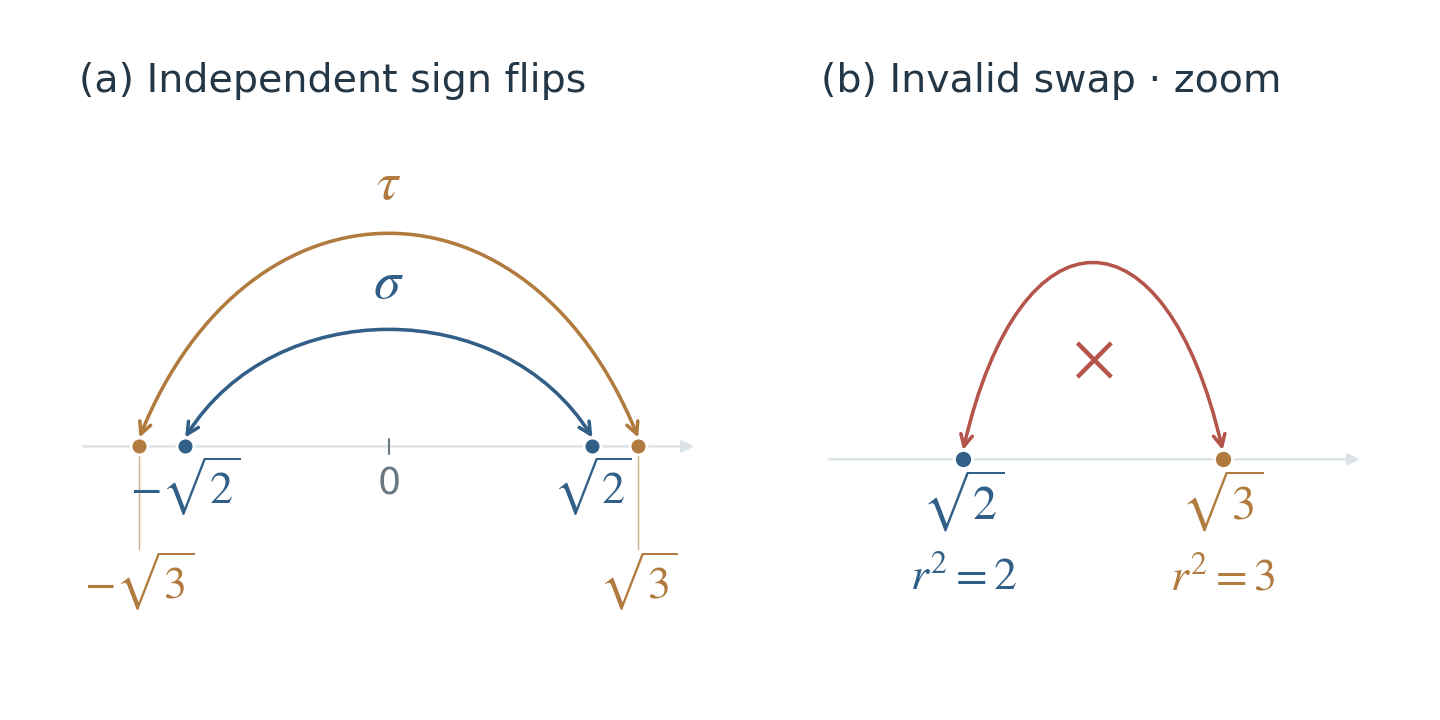

*Figure 3. Panel (a) places the roots at their actual real values. Each sign flip stays within one square-value family. Panel (b) uses a separate horizontal scale to enlarge the forbidden exchange between roots whose squares are $2$ and $3$.*


**Allowed root permutations:** [Open the browser activity](https://pilkwangkim.github.io/posts/Galois-Theory-From-Scratch/#lab-galois-permutations).


Browse the $24$ permutations. Check the image of each square relation and each negative pair. In this example these checks are sufficient: every surviving map is one of the sign changes in (17), and (18) extends it to the whole field.

## 7. Galois correspondence: more fixed numbers, fewer symmetries

A **subgroup** $H\le G$ is a subset that contains the identity and is closed under composition and inverses; $\le$ here means “is a subgroup of,” not a numerical inequality. Take $G=\operatorname{Gal}(L/F)$, the allowed arithmetic-preserving maps of $L$ that fix $F$. In the quartic example, $\lbrace e,\sigma\rbrace $ is a subgroup because $\sigma^2=e$. The set $\lbrace e,\sigma,\tau\rbrace $ is not: composing $\sigma$ and $\tau$ produces $\sigma\tau$, which is missing. For any subgroup, its **fixed field** consists of the numbers that every map in that subgroup leaves unchanged:

$$
\begin{gathered}
L^H=\{u\in L:\sigma(u)=u\\
\text{for every }\sigma\in H\}.
\end{gathered}
\tag{20}
$$

The superscript $H$ labels the maps being tested; it is not an exponent. An element $u$ belongs to $L^H$ only if all those maps fix it. This set really is a field: if every map fixes $u$ and $v$, it also fixes $u+v$, $u-v$, $uv$, and $u/v$ when $v\ne0$.

Conversely, an **intermediate field** is a field $E$ containing the base field $F$ and contained in $L$; for example, $\mathbb Q\subseteq\mathbb Q(\sqrt3)\subseteq\mathbb Q(\sqrt2,\sqrt3)$. It specifies the subgroup of maps that leave every number of $E$ unchanged:

$$
\begin{gathered}
\operatorname{Gal}(L/E)\\
=\{\sigma\in G:\sigma(u)=u\\
\text{for every }u\in E\}.
\end{gathered}
\tag{21}
$$

“Fixing a field” means fixing every element individually, not merely mapping the field onto itself. For example, $\sigma$ maps $\mathbb Q(\sqrt2)$ onto the same set, but sends $\sqrt2$ to $-\sqrt2$. It does not fix that field **pointwise**. In contrast, it fixes every $a+c\sqrt3$ with rational $a,c$.

In the quartic example, $(a,b,c,d)$ represents $a+b\sqrt2+c\sqrt3+d\sqrt6$, with rational coefficients. The map $\sigma$ sends these coordinates to $(a,-b,c,-d)$. Equality with the original vector requires $b=-b$ and $d=-d$, hence $b=d=0$. Exactly the numbers $a+c\sqrt3$ remain, so

$$
L^{\langle\sigma\rangle}=\mathbb Q(\sqrt3).
\tag{22}
$$

Here $\langle\sigma\rangle=\lbrace e,\sigma\rbrace $ is the subgroup generated by $\sigma$. Similarly,

$$
\begin{aligned}
L^{\langle\tau\rangle}&=\mathbb Q(\sqrt2),\\
L^{\langle\sigma\tau\rangle}&=\mathbb Q(\sqrt6),\\
L^G&=\mathbb Q,\qquad L^{\{e\}}=L.
\end{aligned}
\tag{23}
$$

The product $\sigma\tau$ fixes $\sqrt6$ because it changes both signs: $(-\sqrt2)(-\sqrt3)=\sqrt6$. It still moves $\sqrt2$ and $\sqrt3$ individually. Thus fixing a product need not mean fixing its factors.


#### Find a fixed field by solving a linear system


This is also a simultaneous-eigenspace calculation. The fixed vectors lie in the intersection of the kernels of $\sigma-I$ for the selected maps. In the ordered basis $(1,\sqrt2,\sqrt3,\sqrt6)$, $\sigma=\operatorname{diag}(1,-1,1,-1)$, so $\sigma-I=\operatorname{diag}(0,-2,0,-2)$. Its kernel consists of coordinates $(a,0,c,0)$, namely $a+c\sqrt3$.

If both $\sigma$ and $\tau$ must fix the vector, the first condition gives $b=d=0$ and the second gives $c=d=0$. Only the rational coordinate $a$ survives. This is how intersecting the kernels gives $L^G=\mathbb Q$.



### The finite fundamental theorem

For a finite Galois extension $L/F$, the assignments

$$
\begin{gathered}
E\longmapsto\operatorname{Gal}(L/E),\\
H\longmapsto L^H.
\end{gathered}
\tag{24}
$$

are inverse bijections between intermediate fields and subgroups: each object has exactly one partner, and going from a field to its fixing subgroup and back recovers the original field. The same round trip recovers a starting subgroup. They reverse inclusion: if $E_1\subseteq E_2$, fixing every element of $E_2$ imposes at least the conditions for fixing $E_1$, so $\operatorname{Gal}(L/E_2)\subseteq\operatorname{Gal}(L/E_1)$. Their sizes satisfy

$$
\begin{aligned}
[L:L^H]&=\lvert H\rvert,\\
[L^H:F]&=\frac{\lvert G\rvert}{\lvert H\rvert},\\
[L:F]&=\lvert G\rvert.
\end{aligned}
\tag{25}
$$

The **order** $\lvert H\rvert$ is the number of maps in $H$, whereas $[L:E]$ is a vector-space dimension. The theorem equates these two different kinds of count. For $H=\lbrace e,\sigma\rbrace $, there are $2$ maps out of $4$, and its fixed field $\mathbb Q(\sqrt3)$ has degree $4/2=2$ over $\mathbb Q$. The remaining extension $L/\mathbb Q(\sqrt3)$ has degree $2$, recovering the tower-law product $4=2\cdot2$. The ratio $\lvert G\rvert/\lvert H\rvert$ is called the subgroup's **index**, written $[G:H]$; here it is $2$. It counts equal-sized blocks of maps, rather than basis vectors. [Milne, §3](https://www.jmilne.org/math/CourseNotes/FT.pdf)


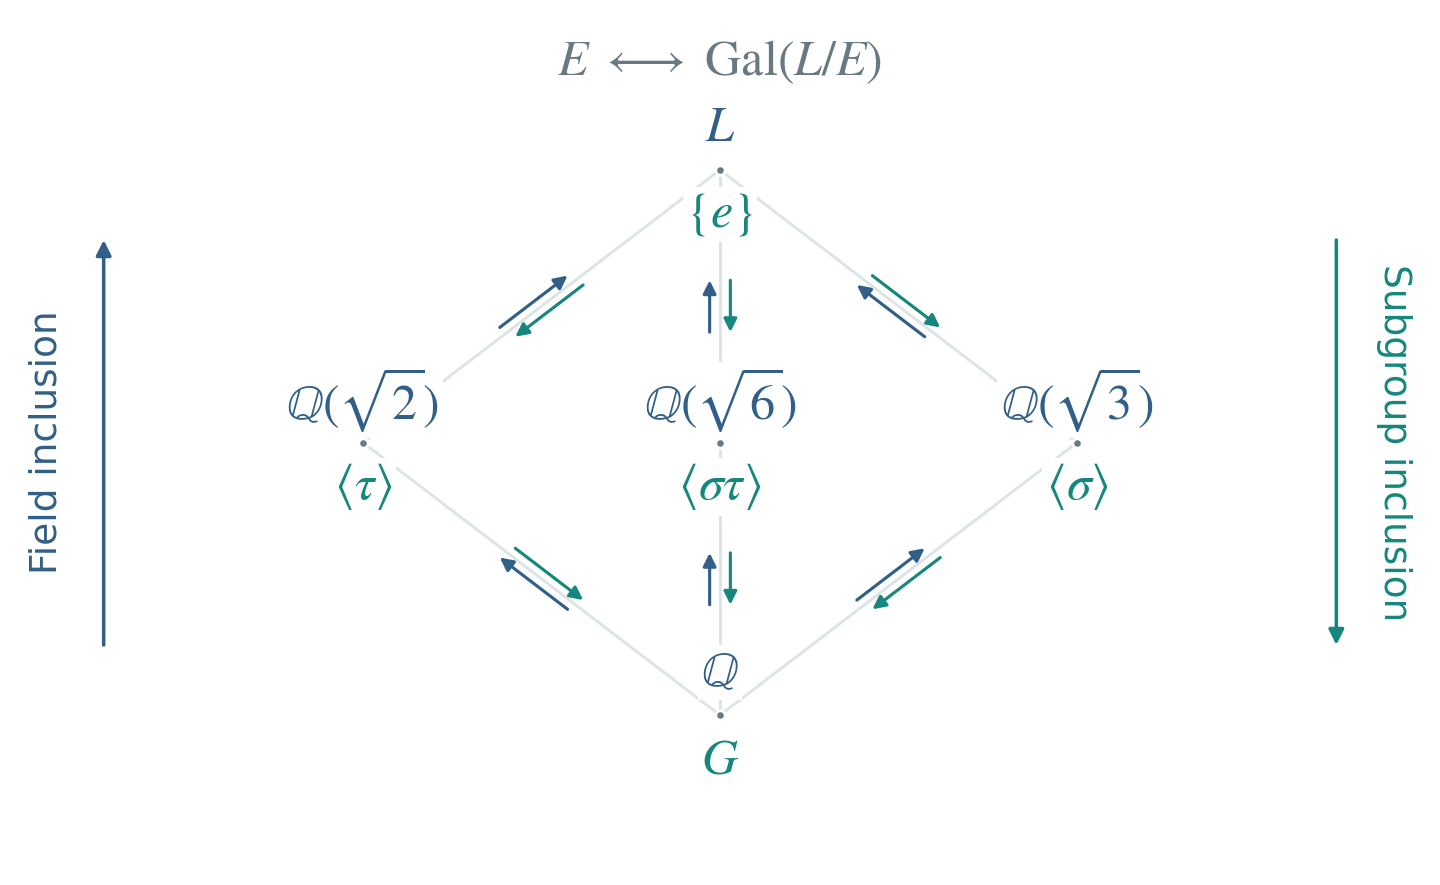

*Figure 4. Each vertex pairs a blue field $E$ with its teal fixing subgroup $\operatorname{Gal}(L/E)$. A line joins neighboring inclusions; longer chains also imply inclusion. Field inclusion runs upward, while subgroup inclusion runs downward. This way of drawing an inclusion relation is called a Hasse diagram.*


**Subgroups and fixed fields:** [Open the browser activity](https://pilkwangkim.github.io/posts/Galois-Theory-From-Scratch/#lab-galois-correspondence).


Choose generators and inspect both their closure and the surviving coefficient directions. Selecting $\sigma$ and $\tau$ also includes $\sigma\tau$; a generated subgroup must contain compositions.


#### Why the correspondence is exact: the counting argument


Two finite-extension facts supply the proof.

An **$F$-embedding** preserves arithmetic and fixes $F$, but may send numbers into a larger field. It is **injective**: two distinct inputs cannot have the same image. For example, $a+b\sqrt2\mapsto a-b\sqrt2$ embeds $\mathbb Q(\sqrt2)$ into $\mathbb C$ while fixing $\mathbb Q$. If two images agree, subtracting them and using the independence of $1,\sqrt2$ forces the two input coefficients to agree. Its image is still $\mathbb Q(\sqrt2)$, not all of $\mathbb C$; an embedding need not fill its target.

For $\alpha=\sqrt[3]2$, the field $\mathbb Q(\alpha)$ has three embeddings into $\mathbb C$, given by sending $\alpha$ to $\alpha$, $\alpha\omega$, or $\alpha\omega^2$ and substituting that choice into every rational expression in $\alpha$. Only the first has its image in the original real field. An automorphism, in contrast, must be an invertible map from the field onto itself.

An **algebraic closure** of $F$ is a field of algebraic elements over $F$ in which every nonconstant polynomial with coefficients in that field splits completely. It provides one place containing every algebraic root we might need. For $\mathbb Q$, the complex algebraic numbers form such a field: they contain $\sqrt2$, $i$, and all the cubic roots above.

First, a degree-$d$ finite separable extension has exactly $d$ embeddings into an algebraic closure that fix its base field. For an extension $F(\alpha)$ generated by one number, the image of $\alpha$ must be a root of its minimal polynomial, giving $d$ choices. For a tower, these choices multiply as dimensions do. Separability ensures that the choices are distinct; in characteristic zero it holds automatically. Normality ensures that the embeddings of a splitting field land back in that field, hence are automorphisms.

Second, if a finite group $H$ acts on a field $L$ by automorphisms, then $[L:L^H]=\lvert H\rvert$. The linear-algebra content of this **fixed-field theorem** is as follows.

Let $h=\lvert H\rvert$. If $x_1,\ldots,x_m$ are independent over $L^H$ with $m>h$, the $h$ equations

$$
\sum_{j=1}^{m}\sigma(x_j)y_j=0,
\qquad \sigma\in H
\tag{26}
$$

have a nonzero solution $y\in L^m$: there are more unknowns than equations. Choose one with the fewest nonzero coordinates and divide all coordinates by one nonzero coordinate to make it $1$. Applying any $\tau\in H$ to every coefficient and unknown only permutes the equations, since $\tau\sigma$ runs through $H$ again. Thus $\tau(y)-y$ is another solution. Its normalized coordinate is $1-1=0$, and coordinates that were zero stay zero, so it would have fewer nonzero coordinates unless the entire difference were zero. Minimality therefore forces every $y_j$ to be fixed by $H$. The row for $\sigma=e$ in (26) would then give a nonzero $L^H$-linear relation among the $x_j$, a contradiction. Thus the dimension is at most $h$. It is at least $h$ because a degree-$d$ extension has at most $d$ distinct base-fixing embeddings, while $H$ supplies $h$ of them.

For any intermediate $E$, the extension $L/E$ is still a separable splitting field, so $\lvert\operatorname{Gal}(L/E)\rvert=[L:E]$. Its fixed field contains $E$ and has the same extension degree below $L$; the tower law therefore makes it equal to $E$. Conversely, $H\subseteq\operatorname{Gal}(L/L^H)$, and both have order $[L:L^H]=\lvert H\rvert$, so they are equal.

The real field $\mathbb Q(\sqrt[3]2)$ shows why normality matters: it has degree $3$ but only the identity as a $\mathbb Q$-automorphism. Its other two embeddings leave the real field.




## 8. The cubic: a nonabelian group can still allow radical formulas


Return to $L=\mathbb Q(\sqrt[3]2,\omega)$, of degree $6$, and write $\alpha=\sqrt[3]2$. Give the roots $\alpha,\omega\alpha,\omega^2\alpha$ the labels $1,2,3$, respectively. An automorphism is determined by its action on these roots. This is a splitting field in characteristic zero, so (25) gives six automorphisms. There are only six permutations of three labels, so every permutation occurs and the group is $S_3$.

One map, $\rho=(123)$, rotates the roots:

$$
\rho(\alpha)=\omega\alpha,\qquad
\rho(\omega)=\omega.
\tag{27}
$$

Complex conjugation $c=(23)$ fixes the real root and exchanges the other two:

$$
c(\alpha)=\alpha,\qquad c(\omega)=\omega^2.
\tag{28}
$$

The order matters even when we inspect just $\alpha$: $\rho c(\alpha)=\omega\alpha$, whereas $c\rho(\alpha)=\omega^2\alpha$. In the first product, $c$ fixes $\alpha$ before $\rho$ rotates it; in the second, $\rho$ rotates it before $c$ exchanges the nonreal pair. The relations $\rho^3=c^2=e$ say that three rotations or two reflections return every root to its starting point. The relation $c\rho c^{-1}=\rho^{-1}$ says that reflection reverses the rotation, just as for a triangle.


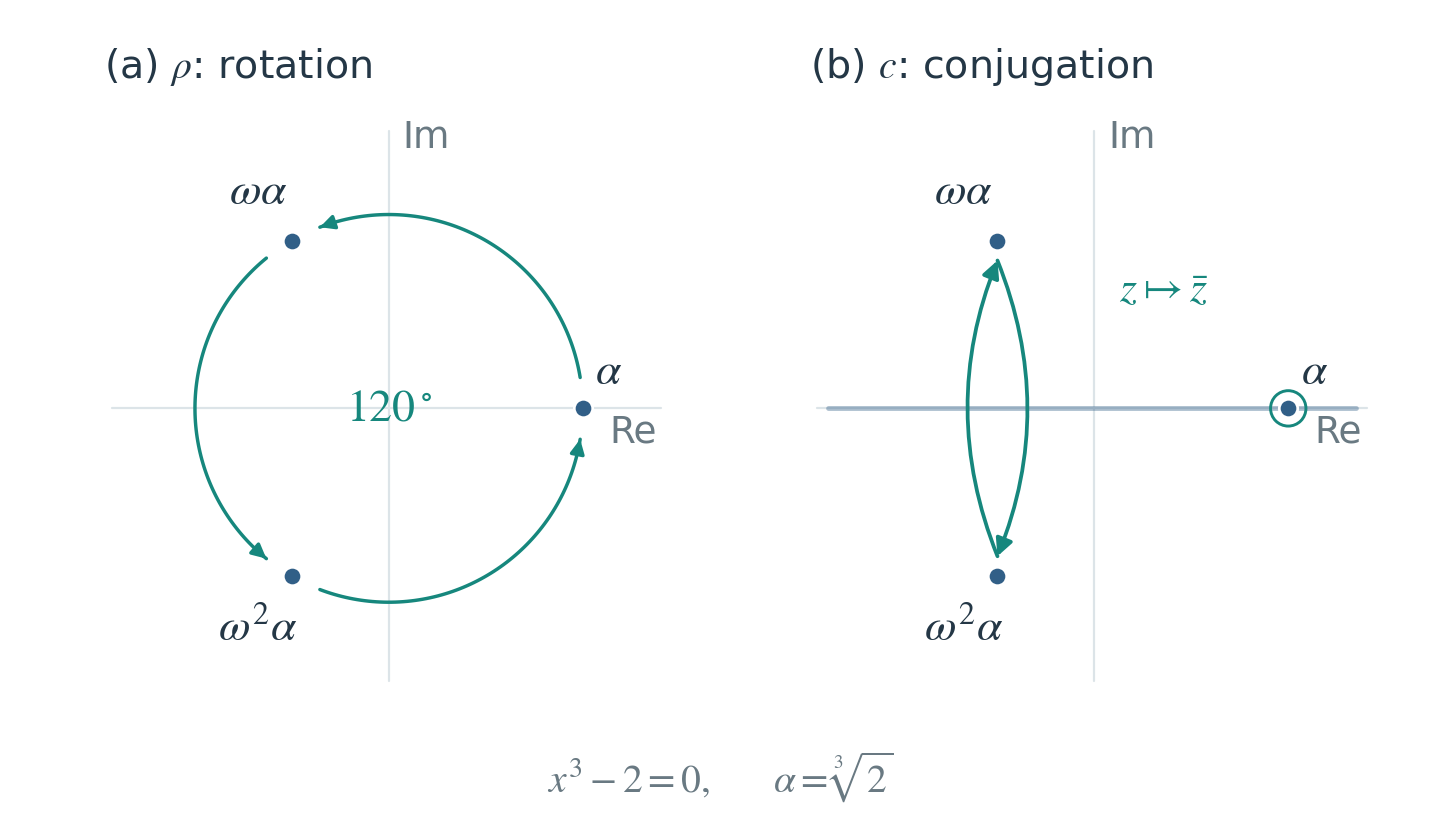

*Figure 5. The actual roots of $x^3-2$ lie at radius $\alpha=\sqrt[3]2$. On this root set, $\rho$ acts as a $120^\circ$ rotation; complex conjugation $c$ reflects across the real axis, fixing $\alpha$ and exchanging the nonreal pair.*

Noncommutativity cannot by itself forbid radicals: all three roots $\alpha,\omega\alpha,\omega^2\alpha$ already have radical expressions. The obstruction must therefore distinguish this nonabelian group from the group of a quintic whose roots cannot be expressed by radicals.

### Where square and cube roots enter Cardano's formula

For a general cubic, write a candidate root as $x=u+v$. The expansion contains a mixed term involving $uv$; choosing this product appropriately leaves two conditions on $u^3,v^3$. These conditions form a quadratic. Its formula supplies square roots, and recovering $u,v$ supplies cube roots. Thus a nonabelian symmetry group can still correspond to a calculation built from radicals.


#### Cardano's calculation, with a numerical-coefficient example


For $Ax^3+Bx^2+Cx+D=0$ with $A\ne0$, divide by $A$ and substitute $x=y-B/(3A)$. The $y^2$ terms cancel. Renaming $y$ as $x$ gives a **depressed cubic**, meaning that its quadratic term is absent:

$$
x^3+px+q=0.
\tag{29}
$$

Set $x=u+v$. Expanding gives $u^3+v^3+q+(3uv+p)(u+v)=0$. Choose $uv=-p/3$ and $u^3+v^3=-q$. Then $u^3v^3=-p^3/27$, so $u^3,v^3$ are the roots of

$$
t^2+qt-\frac{p^3}{27}=0.
\tag{30}
$$

Applying the quadratic formula gives

$$
\begin{aligned}
u^3&=-\frac q2+\sqrt{\Delta},\\
v^3&=-\frac q2-\sqrt{\Delta},\\
\Delta&=\left(\frac q2\right)^2
       +\left(\frac p3\right)^3.
\end{aligned}
\tag{31}
$$

For example, $x^3+3x+1=0$ has $p=3$, $q=1$, and $\Delta=5/4$. Thus $u^3=(-1+\sqrt5)/2$ and $v^3=(-1-\sqrt5)/2$. Choose the real cube root $u$ of the positive first value, then set $v=-1/u$. This guarantees $uv=-1$, and cubing verifies the required value of $v^3$. The number $u+v$ is consequently a root of the original cubic.

A nonzero complex number has three cube roots; choosing a **branch** here means choosing one of those three values. The choices for $u$ and $v$ must satisfy $uv=-p/3$, so they cannot be made independently. If $u\ne0$, choose $u$ first and define $v=-p/(3u)$. Replacing them by $\omega^k u$ and $\omega^{-k}v$ keeps the product unchanged and gives all three roots, counting multiplicity. If $p=0$, simply solve $x^3=-q$, including $p=q=0$.

Even when the final roots are real, intermediate radical values can be complex. The definition of radical solvability allows those values.



## 9. Normal subgroups, quotients, and commutators

A group can be nonabelian overall while becoming abelian after some transformations are grouped together. A **quotient group** makes that grouping precise.

Use the earlier quartic group $G=\lbrace e,\sigma,\tau,\sigma\tau\rbrace $, where $\sigma$ flips $\sqrt2$ and $\tau$ flips $\sqrt3$. Let $H=\lbrace e,\sigma\rbrace $. Composing $\tau$ on the left with every member of $H$ gives $\tau H=\lbrace\tau e,\tau\sigma\rbrace=\lbrace\tau,\sigma\tau\rbrace$, since these sign changes commute. The two sets $H$ and $\tau H$ partition all four transformations: every map belongs to exactly one of the two sets.

Such a set $gH=\lbrace gh:h\in H\rbrace $ is a **left coset**: a copy of the subgroup obtained by composing the same map $g$ with each of its elements. Multiplication by $g$ can be undone by $g^{-1}$, so it neither merges nor loses elements. Each coset therefore has $\lvert H\rvert$ elements; distinct cosets do not overlap. The **index** $[G:H]$ counts these cosets. Here it is $2$, and $4=2\cdot2$ is the instance of

$$
\lvert G\rvert=[G:H]\,\lvert H\rvert.
\tag{32}
$$

### Quotients distinguish actions, rather than individual maps

Consider only the numbers in $E=\mathbb Q(\sqrt3)$. Both elements of $H$ act as the identity on $E$, even though $\sigma$ is not the identity on the larger field. Both elements of $\tau H$ instead send $\sqrt3$ to $-\sqrt3$. Four transformations of $L$ therefore give just two different transformations of $E$.

Each coset is now treated as a single **class** of indistinguishable maps on $E$. The class $H$ does nothing to $E$, while $\tau H$ changes the sign of $\sqrt3$. Their multiplication is $H\cdot H=H$, $H\cdot\tau H=\tau H\cdot H=\tau H$, and $\tau H\cdot\tau H=H$. For the last product, choosing $\tau$ from each class gives $\tau^2=e\in H$; choosing $\sigma\tau$ instead still gives a product in $H$.

These two classes form $G/H\cong C_2$. The symbol $\cong$ means **isomorphic**: after renaming the two classes as the two elements of $C_2$, the multiplication agrees exactly. The quotient does not delete half the maps or divide each map by $H$: it treats maps with the same restricted action as one element.

A **group homomorphism** is a map $\phi$ from one group to another that preserves composition: $\phi(gh)=\phi(g)\phi(h)$. Here $\phi(g)$ is the **restriction** of $g$ to $E$: use the same rule, but allow only inputs from $E$. Composing and then restricting gives the same result as composing the restrictions, so this is a homomorphism. Explicitly, $\phi(e)=\phi(\sigma)=\operatorname{id}_E$, while $\phi(\tau)=\phi(\sigma\tau)$ is the sign-changing map on $E$.

Its **kernel** consists of inputs sent to the identity of the target group; here it is exactly $H$. This resembles the kernel of a linear map, with the group identity replacing the zero vector. The restriction is **surjective** onto the two-element automorphism group of $E/F$: both possible maps on $E$ occur. It is not **injective**, because distinct maps such as $e,\sigma$ have the same image. Thus a quotient can lose distinctions between maps without losing any of the resulting actions on the smaller field.

### Why normality is necessary

A coset multiplication must not depend on which **representative**, or member of the class, we choose. Multiplying $gN$ and $hN$ is supposed to give $ghN$, even if $g$ or $h$ is replaced by another member of the same class. The required condition is that $N$ be a **normal subgroup**: $gNg^{-1}=N$ for every $g\in G$. Here $gNg^{-1}$ means the set of all $gng^{-1}$ with $n\in N$. Normality says that this operation may rearrange the subgroup's elements but never changes the subgroup as a set.

The operation $h\mapsto ghg^{-1}$ is **group conjugation**. For a permutation, it relabels the action of $h$: for instance, $(123)(12)(132)=(23)$. More generally, $g(ab)g^{-1}=(g(a)\,g(b))$. This is different from complex conjugation $z\mapsto\bar z$: one acts on group elements, while the other is a particular map on numbers.

Our $V_4$ example is abelian, so $ghg^{-1}=h$; for instance, $\tau\sigma\tau^{-1}=\sigma$. Thus $H$ is normal. The same argument does not work in an arbitrary nonabelian group. The notation $H\triangleleft G$ means “$H$ is normal in $G$.” For a finite Galois extension, the exact field–group statement is

$$
\begin{gathered}
E/F\text{ is Galois}\iff H\triangleleft G,\\
\operatorname{Gal}(E/F)\cong G/H.
\end{gathered}
\tag{33}
$$

Here $G=\operatorname{Gal}(L/F)$ and $E=L^H$. The two uses of **normal** concern different objects. For a field extension $E/F$, it means that every irreducible polynomial over $F$ with a root in $E$ has all its roots there. For a subgroup $H$, it means that conjugation preserves $H$ as a set. Equation (33) connects these definitions. A normal $H$ ensures that every map of $L$ sends $E$ back to itself. Restricting all maps then gives every automorphism of $E/F$; its kernel is $H$, producing the quotient.


#### A subgroup of S3 that cannot define a quotient group


In the cubic example, let $\rho=(123)$, $c=(23)$, and $H=\lbrace e,c\rbrace $. Direct composition gives $\rho H=\lbrace (123),(12)\rbrace $, but $H\rho=\lbrace (123),(13)\rbrace $. Thus the left and right cosets differ. Relabeling also gives $\rho H\rho^{-1}=\lbrace e,(13)\rbrace \ne H$, so $H$ is not normal.

The product of classes actually becomes ambiguous. The maps $e,c$ represent the same class $H$, but multiplying them by $\rho$ gives $e\rho=(123)$ and $c\rho=(13)$. These lie in different left cosets, because $(13)$ is not in $\rho H$. Thus “multiply $H$ by $\rho H$” has no single answer independent of the representative.

This subgroup fixes the real field $\mathbb Q(\sqrt[3]2)$, which is not Galois over $\mathbb Q$. Restricting every splitting-field automorphism to that real field would not give maps from the real field to itself.

By contrast, the rotation subgroup $N=\lbrace e,\rho,\rho^2\rbrace $ is normal: reflection exchanges $\rho$ with $\rho^{-1}$ but leaves the set unchanged. Its two cosets are the rotations and the three reflections. They form $S_3/N\cong C_2$, matching the two automorphisms of the fixed field $\mathbb Q(\omega)/\mathbb Q$.



### Measuring what remains after forcing commutativity

The **commutator** of $g,h$ is

$$
[g,h]=ghg^{-1}h^{-1}.
\tag{34}
$$

It compares the two orders of composition: $gh=[g,h]hg$, so it is the identity exactly when $gh=hg$. This is a multiplicative group commutator, not the matrix expression $gh-hg$. For example, with rightmost-first composition, $[(12),(23)]=(132)$. Applying the four factors to each label gives the images $1\mapsto3$, $2\mapsto1$, $3\mapsto2$.

The **derived subgroup** $G'$ is the smallest subgroup containing all commutators: include their products and inverses until the set is closed. The prime is a name for this operation, not a derivative. For an abelian group such as $V_4$, every commutator is $e$, so $V_4'=\lbrace e\rbrace$. For $S_3$, the 3-cycle just found generates $\lbrace e,(123),(132)\rbrace $. Checking the six transformations shows that every commutator belongs to this set, so it is exactly $S_3'$. It is a cyclic group of order $3$.

The subgroup $G'$ is normal because relabeling a commutator gives another commutator:

$$
k[g,h]k^{-1}=[kgk^{-1},khk^{-1}].
\tag{35}
$$

In $G/G'$, every commutator belongs to the identity class, so the quotient is abelian. Conversely, if $G/N$ is abelian, all commutators lie in $N$, forcing $G'\subseteq N$. Thus $G'$ records precisely the part that any abelian quotient must identify with the identity.

Repeat:

$$
\begin{gathered}
G^{(0)}=G,\\
G^{(j+1)}=(G^{(j)})'.
\end{gathered}
\tag{36}
$$

This is the **derived series**; the superscript $(j)$ counts repetitions, not powers of a group element. At every step use the group left by the preceding step, not the original group again. A finite group is **solvable** when this process reaches $\lbrace e\rbrace $. For the cubic, $S_3'=\lbrace e,(123),(132)\rbrace $ is cyclic, hence abelian. All commutators inside this three-element group are therefore $e$. Its next derived subgroup is $\lbrace e\rbrace $: the orders are $6\to3\to1$. Nonabelian at the beginning does not prevent termination.

Equivalently, a solvable group can be reduced to $\lbrace e\rbrace $ through a chain in which each subgroup is normal in the preceding one and each successive quotient is abelian. The quotient records one abelian layer of the transformations. The derived series supplies such a chain when it reaches the identity group. If it never reaches that group, choosing a different subgroup chain cannot avoid the obstruction.


#### Why a different chain cannot bypass the derived series


Suppose $G=N_0\supseteq N_1\supseteq\cdots\supseteq N_r=\lbrace e\rbrace$, with each $N_{j+1}$ normal in $N_j$ and $N_j/N_{j+1}$ abelian. Commutators in $N_j$ become the identity in this quotient, so $N_j'\subseteq N_{j+1}$. Starting with $G^{(0)}=N_0$, it follows successively that $G^{(1)}\subseteq N_1$, $G^{(2)}\subseteq N_2$, and ultimately $G^{(r)}\subseteq N_r=\lbrace e\rbrace$. Any such chain forces the derived series to terminate too.



## 10. Why radicals lead to solvable groups

A finite radical expression can be evaluated one root extraction at a time. The fields containing the numbers available after each step form a **radical tower**:

$$
\begin{gathered}
F=K_0\subseteq\cdots\subseteq K_r,\\
K_j=K_{j-1}(\alpha_j),\\
\alpha_j^{m_j}\in K_{j-1}.
\end{gathered}
\tag{37}
$$

Here $j$ counts the steps, $m_j\ge2$ is an integer giving the root to extract, and $\alpha_j$ is one chosen value of that root. The condition $\alpha_j^{m_j}\in K_{j-1}$ says that its **radicand**, the quantity under the radical, was available before this step. The notation $K_{j-1}(\alpha_j)$ means that we add $\alpha_j$ and all the results of arithmetic using it and the old field.

For example, start with $K_0=\mathbb Q$, add $\sqrt3$ to obtain $K_1$, then add $\xi=\sqrt{2+\sqrt3}$. The first extraction has exponent $m_1=2$ and radicand $3$; the second has exponent $m_2=2$ and radicand $2+\sqrt3\in K_1$. Arithmetic stays in the current field, while a new radical may require a larger field. There is no requirement that every step enlarge the field: a root already available adds nothing new.

For a polynomial to be solvable by radicals, its splitting field must be **contained in** the final radical field. Equality is not required; a formula may introduce extra intermediate numbers.

Suppose first that the current field $K$ already contains every $m$-th root of unity, the numbers whose $m$-th power is $1$. Choose a primitive one $\zeta_m$, whose powers list all $m$ of them. If $\beta^m=a\in K$ with $a\ne0$, an automorphism fixing $K$ must send $\beta$ to another root of $x^m-a$. These possibilities are

$$
\beta,\ \zeta_m\beta,\ldots,\zeta_m^{m-1}\beta.
\tag{38}
$$

All these roots lie in $K(\beta)$, so $K(\beta)$ is the splitting field of $x^m-a$ over $K$. In characteristic zero it is Galois. Each map fixing $K$ is determined by its choice $\beta\mapsto\zeta_m^k\beta$. If one map has exponent $k$ and another has exponent $\ell$, their composition sends $\beta$ to $\zeta_m^{k+\ell}\beta$: the maps fix $\zeta_m$, so this multiplier stays unchanged when the next map is applied. Exponents wrap around after $m$, since $\zeta_m^m=1$. Adding exponents commutes, so these maps commute. Their group is a subgroup of $C_m$, not necessarily all of $C_m$, and is therefore abelian.

The cubic gives a concrete example. Over $K=\mathbb Q(\omega)$, the map $\beta\mapsto\omega\beta$ for $\beta=\sqrt[3]2$ has three powers. Applying it to $\omega^2\beta$ gives $\omega^3\beta=\beta$. Applying the exponent-$2$ map twice gives $\omega^4\beta=\omega\beta$: $2+2=4$ becomes $1$ modulo $3$, meaning that we keep the remainder after division by $3$. Thus the remaining radical choice has group $C_3$, even though the full group over $\mathbb Q$ was $S_3$.

The roots of unity are essential. The original real extension $\mathbb Q(\sqrt[3]2)/\mathbb Q$ is not Galois, so an arbitrary radical tower cannot be treated directly as a tower of cyclic Galois extensions.


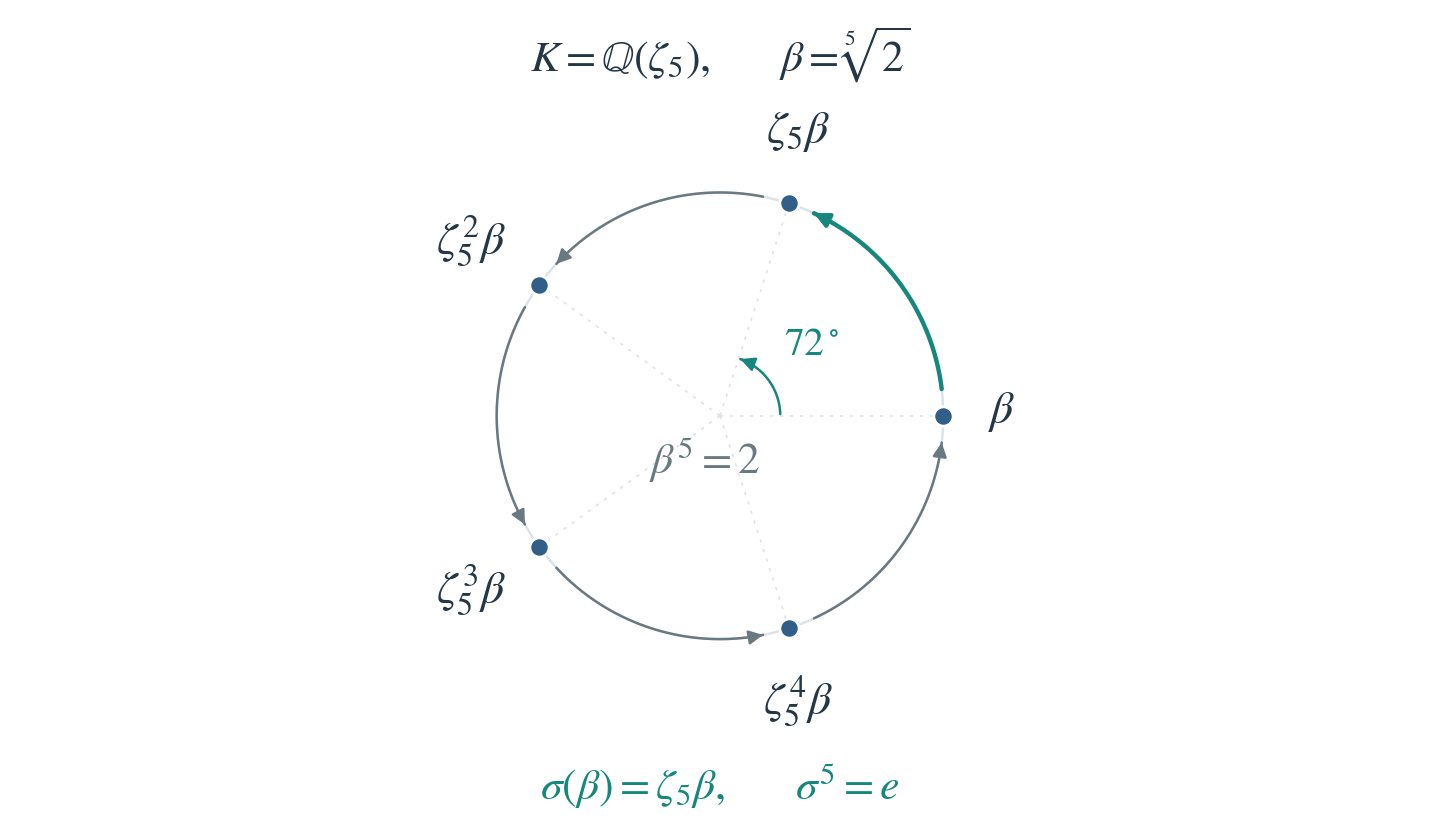

*Figure 6. For $K=\mathbb Q(\zeta_5)$ and $\beta=\sqrt[5]2$, the extension $K(\beta)/K$ has degree $5$. The automorphism $\sigma$ fixes $K$ and sends $\beta$ to $\zeta_5\beta$. On the five roots, its action is a $72^\circ$ rotation, generating $C_5$.*

For a whole tower, the extra difficulty is that a map may change an earlier radicand. The **$F$-conjugates** of an algebraic number are the roots of its minimal polynomial over $F$; equivalently, they are its possible images under arithmetic-preserving maps that fix $F$ and may take values in a larger field. For example, $2+\sqrt3$ has minimal polynomial $t^2-4t+1$ over $\mathbb Q$, so its conjugates are $2+\sqrt3$ and $2-\sqrt3$. Both are real: this use of “conjugate” is not just complex conjugation, and it is not conjugation of group elements either.

Enlarge the tower by adding roots of unity and all roots belonging to every conjugate radicand. This makes the stages Galois, so maps of an earlier field extend to maps of the larger one. At each stage, the kernel of restriction consists of maps that fix the earlier field and change only the new radical choices. Record one multiplier exponent for each new radical; composition adds these coordinates separately, modulo the extraction exponent $m_j$. All these coordinate additions commute, so the kernel is abelian even when several radicals are added together. Each stage therefore adds an abelian layer to the group from the preceding stage; the resulting finite group is solvable. Restricting it to the polynomial's splitting field gives a quotient, which is solvable too. **A finite radical formula therefore requires a solvable Galois group.** This applies to complex intermediate radicals as well.


#### Why an entire radical tower has a solvable Galois closure


The **normal closure** of a finite extension is the smallest normal extension of the base field containing it; it includes all base-field conjugates of its generators. For example, the real field $\mathbb Q(\sqrt[3]2)$ is not normal, because $x^3-2$ has two missing roots. Including those roots gives $\mathbb Q(\sqrt[3]2,\omega)$, its normal closure. In characteristic zero this is a Galois extension. The construction below may add more numbers than the minimal normal closure, which is harmless for containing the original roots.

Work in one algebraic closure of a characteristic-zero field $F$, a common field containing all algebraic roots needed by the calculation. Choose $N$ divisible by all extraction exponents $m_j$, and begin with $T_0=F(\zeta_N)$. Its automorphisms send $\zeta_N$ to powers $\zeta_N^u$ that are still primitive. Composing these maps multiplies their exponents modulo $N$, and these multiplications commute. Thus the initial Galois group is abelian.

At stage $j$, include all roots of $x^{m_j}-a$ for every $F$-conjugate $a$ of the radicand. This gives fields $T_j$ that contain the original radical tower and are finite Galois extensions of $F$.

A map fixing $T_{j-1}$ multiplies each new nonzero radical by a root of unity. Record one multiplier for each chosen radical. Composition multiplies these coordinates separately, so the resulting group is abelian. Restriction onto $\operatorname{Gal}(T_{j-1}/F)$ is surjective: every automorphism of the earlier field extends to at least one automorphism of $T_j$. Its kernel is $\operatorname{Gal}(T_j/T_{j-1})$, precisely the maps just described. If the earlier group is solvable, enough derived steps have trivial image there and therefore lie in this abelian kernel. One further step reaches the identity. Induction makes $\operatorname{Gal}(T_r/F)$ solvable.

If $L$ is the polynomial's splitting field, $L\subseteq T_r$. Restriction gives

$$
\operatorname{Gal}(T_r/F)
\twoheadrightarrow\operatorname{Gal}(L/F).
\tag{39}
$$

The two-headed arrow means that restriction is surjective: every automorphism of $L/F$ occurs. The kernel is $\operatorname{Gal}(T_r/L)$, so the target is the quotient by the maps invisible on $L$. A homomorphism sends commutators to commutators, since it preserves products and inverses. The image of a derived series reaching the identity therefore reaches the identity too, so this quotient is solvable. Hence

$$
\begin{gathered}
f\text{ solvable by radicals}\\
\Longrightarrow\\
\operatorname{Gal}(L/F)\text{ solvable}.
\end{gathered}
\tag{40}
$$

The enlargement at each stage can be specified exactly. Suppose $T_{j-1}/F$ is Galois and contains $K_{j-1}$, with $\alpha_j^{m_j}=a_j$. Adjoin all roots of

$$
\begin{gathered}
x^{m_j}-\sigma(a_j),\\
\sigma\in\operatorname{Gal}(T_{j-1}/F)
\end{gathered}
\tag{41}
$$

to obtain $T_j$. Every $F$-embedding permutes these polynomials and their roots, proving normality; characteristic zero supplies separability. The field contains $\alpha_j$, hence $K_j$.

For each nonzero conjugate radicand, choose one nonzero root $\beta$. Since $\zeta_{m_j}\in T_{j-1}$, these choices generate the whole extension. For $g$ fixing $T_{j-1}$, record the ratios $g(\beta)/\beta$. This is an injective homomorphism into a product of root-of-unity groups: composition multiplies the ratios separately, and a map with every ratio equal to $1$ fixes all the generators, hence the entire field. A zero radicand contributes no extension. This establishes the abelian-kernel assertion without assuming that the original radical tower was Galois. [Sharifi, Theorem 10.3.10](https://www.math.ucla.edu/~sharifi/notes/algebra-ch10.html)



## 11. Why solvable groups give radicals: an eigenvector argument

The converse completes **Galois's solvability criterion**. In characteristic zero,

$$
\boxed{
\begin{gathered}
f\text{ solvable by radicals}\\
\iff\\
\operatorname{Gal}(L/F)\text{ solvable}
\end{gathered}}
\tag{42}
$$

where $L$ is the splitting field of $f$ over $F$. [Milne, Theorem 3.28 and §5](https://www.jmilne.org/math/CourseNotes/FT.pdf)

The quadratic example shows the linear-algebra mechanism. On $E=\mathbb Q(\sqrt2)$, the automorphism $\sigma(a+b\sqrt2)=a-b\sqrt2$ has matrix $\operatorname{diag}(1,-1)$ in the basis $(1,\sqrt2)$. Its eigenvector $\beta=\sqrt2$ has eigenvalue $-1$. Squaring removes that sign change: $\sigma(\beta^2)=(-\beta)^2=\beta^2$. The number $\beta^2$ is therefore in the fixed field $\mathbb Q$; here it is $2$. Recovering $\beta$ from this fixed value is exactly one square-root extraction. The important link is not just that $\sigma$ has eigenvectors: a suitable power of an eigenvector is fixed by every map in the group.

A **cyclic extension** is a Galois extension whose Galois group is cyclic. When its degree is a prime $p$, a suitable eigenvector similarly has a $p$-th power in the fixed field. After the needed roots of unity are present, each such stage can therefore be obtained by one radical. A solvable group's abelian quotient stages can be divided into cyclic stages of prime order. For example, $S_3\supset C_3\supset\lbrace e\rbrace$ has quotients of orders $2$ and $3$, matching square-root and cube-root stages. Galois correspondence reverses the group chain to give the field extensions. The forward implication from section 10 is the part that rules out a radical formula for a nonsolvable group; the converse explains why the solvable cases really do have formulas.


#### The general cyclic-stage eigenvector proof


Suppose $E/K$ is Galois with cyclic group of prime order $p$, generated by $\sigma$, and $\zeta_p\in K$. Its maps are $I,\sigma,\ldots,\sigma^{p-1}$, where $I$ is the identity operator. The dimension formula (25) makes $E$ a $p$-dimensional vector space over $K$, and fixing $K$ makes $\sigma$ a $K$-linear operator.

We can substitute an operator into a polynomial: for instance, $q(t)=t^2-1$ gives $q(\sigma)=\sigma^2-I$. An **operator minimal polynomial** is the nonzero monic polynomial $q(t)$ of least degree for which this substitution gives the zero operator. It is a relation among powers of a map, whereas the earlier minimal polynomial of a number is a relation among powers of that number. For the quadratic map $\operatorname{diag}(1,-1)$, the operator minimal polynomial is $t^2-1$: its square is $I$, but neither $\sigma-I$ nor $\sigma+I$ is zero.

Because $\sigma^p=I$, its operator minimal polynomial divides $t^p-1$. Indeed, polynomial division writes any annihilating polynomial as a multiple of $q$ plus a smaller-degree remainder; substituting $\sigma$ makes that remainder zero too, so minimality forces the remainder to be zero. Here

$$
t^p-1=\prod_{j=0}^{p-1}(t-\zeta_p^j).
\tag{43}
$$

The factors are distinct in characteristic zero. An operator annihilated by a product of distinct linear factors has an eigenbasis: every vector can be separated into components with those eigenvalues. Thus $\sigma$ is **diagonalizable over $K$**, meaning that a basis of eigenvectors with coefficients in $K$ makes its matrix diagonal. The explicit component operators in the separate calculation below verify this decomposition. If every eigenvalue were $1$, this eigenbasis would make $\sigma=I$. Since $\sigma$ is not the identity, some nonzero eigenvector $\beta$ has eigenvalue $\zeta_p^j\ne1$:

$$
\begin{gathered}
\sigma(\beta)=\zeta_p^j\beta\\
\Longrightarrow
\sigma(\beta^p)=\beta^p.
\end{gathered}
\tag{44}
$$

If $\sigma$ fixes $\beta^p$, so do all its powers, which are every element of the cyclic group. The fixed field is $K$, hence $\beta^p\in K$. For $0\le k<p$, the images are $\sigma^k(\beta)=\zeta_p^{jk}\beta$. They are distinct: since $p$ is prime and $j\ne0$, the equality $\zeta_p^{jk}=\zeta_p^{j\ell}$ forces $k=\ell$ in this range. Each image is a root of the minimal polynomial of the **number** $\beta$ over $K$, so that polynomial's degree is at least $p$. It is at most $[E:K]=p$, giving

$$
E=K(\beta),\qquad \beta^p\in K.
\tag{45}
$$

For a finite solvable group, refine its abelian quotient stages into cyclic prime-order stages. A concrete refinement is $V_4\supset\lbrace e,\sigma\rbrace\supset\lbrace e\rbrace$: both quotient orders are $2$, although $V_4$ itself is not cyclic. In a general finite abelian group, choose a **proper subgroup**, one smaller than the whole group, that cannot be enlarged without reaching the whole group. Its quotient has no subgroup strictly between the identity group and itself. Any nonidentity element must therefore generate that quotient, making it cyclic. Its order must be prime: if the cyclic group had composite order $ab$ with $a,b>1$ and generator $g$, the powers of $g^a$ would give a subgroup of order $b$, strictly between those two endpoints. Repeat within the chosen subgroup. Applying these refinements to the original quotient stages gives a chain with cyclic prime-order quotients. Galois correspondence reverses it into field extensions of those degrees.

For $G=\operatorname{Gal}(L/F)$, set $F'=F(\zeta_{\lvert G\rvert})$ and $L'=LF'$, the smallest field containing both $L$ and $F'$. The root of unity need not already lie in $L$. Adjoining it is a radical step because $\zeta_{\lvert G\rvert}^{\lvert G\rvert}=1$.

The extension $L'/F'$ is the splitting field of the same polynomial over the enlarged base. Restricting its automorphisms to $L$ gives a homomorphism into $G$. It is injective: if two maps agree on $L$, they also agree on $F'$ because both fix it. They therefore agree on every arithmetic expression generating $L'$, so they are the same map. Thus the new group has exactly the multiplication of a subgroup of $G$ and remains solvable: its derived subgroups stay inside those of $G$, which reach the identity. All prime orders in its refined chain divide $\lvert G\rvert$, so $F'$ contains the roots of unity needed at every stage. Applying the cyclic-stage argument over $F'$ produces a radical tower containing $L'$, hence every root of the original polynomial.




#### Why this operator has an eigenbasis


A **projector** is a linear operator $P$ satisfying $P^2=P$: it keeps one component, and applying it again changes nothing. In the quadratic example, $P_0=(I+\sigma)/2$ sends $a+b\sqrt2$ to $a$, while $P_1=(I-\sigma)/2$ sends it to $b\sqrt2$. Each keeps one eigenspace and removes the other. Their sum is $I$, so together they reconstruct every input.

For $j=0,\ldots,p-1$, define the linear operator $P_j=\frac1p\sum_{k=0}^{p-1}\zeta_p^{-jk}\sigma^k$. On an eigenvector with eigenvalue $\zeta_p^{\ell}$, it multiplies by $\frac1p\sum_{k=0}^{p-1}\zeta_p^{(\ell-j)k}$, which is $1$ for $\ell=j$ and $0$ otherwise. These are the general component-selecting operators. To prove that their images really supply all the eigenvectors needed, without assuming an eigenbasis, shift the summation index and use $\sigma^p=I$. This gives $\sigma P_j=\zeta_p^j P_j$, so every nonzero vector in the image of $P_j$ has eigenvalue $\zeta_p^j$.

Also $\sum_jP_j=I$: summing the coefficients of $\sigma^k$ gives $1$ for $k=0$ and $0$ for $1\le k<p$. For the latter, the geometric sum $1+z+\cdots+z^{p-1}$ is zero when $z^p=1$ and $z\ne1$, because multiplying it by $z-1$ gives $z^p-1=0$. Consequently every vector $v$ decomposes as $v=\sum_jP_jv$, a sum of eigenvectors. On these components each $P_j$ acts as identity or zero, so $P_j^2=P_j$. Eigenspaces with different eigenvalues are independent, so choosing bases within them gives an eigenbasis. This proves the diagonalization step directly from finite sums.



## 12. Why degrees two, three, and four behave differently

A **transposition** exchanges two labels and leaves the others fixed: $(12)$ swaps $1$ and $2$. Every permutation can be built from such swaps. For instance, $(123)=(12)(23)$ uses two: applying the right-hand swap first sends $1\to2$, $2\to3$, and $3\to1$. A permutation is **even** if it uses an even number of swaps, and **odd** otherwise. This number is not unique—two identical swaps can always be inserted—but its parity is.

The determinant explains why. Give the labels formal basis vectors $e_1,\ldots,e_n$. The **permutation matrix** $P_\pi$ sends $e_i$ to $e_{\pi(i)}$: its columns are the same basis vectors in a different order. For $(12)$, the columns $e_1,e_2$ are exchanged, so its determinant is $-1$. For $(123)$, the first three columns are $e_2,e_3,e_1$, obtained by two exchanges, so the determinant is $+1$. These vectors represent labels, not the positions or numerical values of the roots.

Matrix multiplication matches composition, and determinants multiply. Thus any decomposition of the same permutation into $k$ swaps gives the same value $\det P_\pi=(-1)^k$. This **sign** distinguishes even from odd permutations without depending on the chosen swaps. The even permutations form the **alternating group** $A_n$: identity, products, and inverses all have determinant $+1$. In the language of section 9, $A_n$ is the kernel of the sign map—the permutations sent to $+1$.

For $n\ge2$, composing with one fixed transposition pairs every even permutation with an odd one. Exactly half of the $n!$ permutations are therefore even: $A_3$ has $3$ elements, $A_4$ has $12$, and $A_5$ has $60$. These are the subgroup orders in the derived series.

For $n\le4$, the derived series terminate:

$$
\begin{aligned}
S_2&\supset\{e\},\\
S_3&\supset A_3\supset\{e\},\\
S_4&\supset A_4\supset V_4\supset\{e\}.
\end{aligned}
\tag{46}
$$

Consequently every subgroup of these $S_n$ is solvable too: taking its commutators stays inside the corresponding derived subgroup of $S_n$.

Here the $V_4$ inside $S_4$ is the double-transposition subgroup $\lbrace e,(12)(34),(13)(24),(14)(23)\rbrace $. Each nonidentity element performs two disjoint swaps; for example, $(12)(34)$ exchanges $1,2$ and also $3,4$. Its multiplication has the same Klein four-group structure as the earlier independent sign changes, but it acts on different objects. All four permutations are even.

The successive quotient orders in the $S_4$ chain are $24/12=2$, $12/4=3$, and $4/1=4$. The last group $V_4$ is abelian, not cyclic: repeating any one nonidentity element gives only that element and $e$. Inserting the subgroup $\lbrace e,(12)(34)\rbrace$ splits this last part into two order-$2$ quotients. Thus only cyclic stages of orders $2$ and $3$ are needed. By the radical–solvability correspondence, these are square-root and cube-root stages, which explains why quartic formulas need no genuinely new type of radical.

### Three pairings explain the cubic step in a quartic

Four root labels have exactly three unordered pairings:

$$
\begin{gathered}
12\mid34,\\
13\mid24,\\
14\mid23.
\end{gathered}
\tag{47}
$$

A permutation of four labels permutes these three pairings. For example, $(12)$ fixes $12\mid34$ and exchanges the other two. The double transpositions fix all three pairings; they form the kernel $V_4$ of the resulting homomorphism $S_4\to S_3$.

A **resolvent** is an auxiliary polynomial that records simpler combinations of the unknown roots. For a quartic with roots $a,b,c,d$, use the three values $ab+cd$, $ac+bd$, and $ad+bc$: one for each pairing. Their sum is $ab+ac+ad+bc+bd+cd$, exactly the $x^2$ coefficient of the monic quartic obtained by multiplying $(x-a)(x-b)(x-c)(x-d)$. The pairwise-product sum and product of the three pairing values can also be rewritten using the original coefficients; their explicit expansions are given below. Negating the sum and product, but keeping the pairwise-product sum, gives the three nonleading coefficients of a monic cubic whose roots are the pairing values. Knowing the four roots in advance is unnecessary.

Solving this cubic determines the three pairing values. The remaining quadratic stages recover the individual root choices. The cubic therefore solves a smaller bookkeeping problem inside the quartic, not a new four-root problem disguised as a three-root one. If pairing values happen to coincide, repeated values must be handled rather than assumed distinct.


#### A concrete resolvent for the earlier quartic


Use $(x^2-2)(x^2-3)$ with ordered roots $a=\sqrt2$, $b=-\sqrt2$, $c=\sqrt3$, $d=-\sqrt3$. The three pairing values are:

- $y_1=ab+cd=-5$.
- $y_2=ac+bd=2\sqrt6$.
- $y_3=ad+bc=-2\sqrt6$.

Their monic cubic is $(t+5)(t^2-24)$, which expands to $t^3+5t^2-24t-120$. It has rational coefficients even though two pairing values contain $\sqrt6$.

For example, the coefficient of $t^2$ is $-(y_1+y_2+y_3)=5$, the coefficient of $t$ is $y_1y_2+y_1y_3+y_2y_3=-24$, and the constant coefficient is $-y_1y_2y_3=-120$. These are the usual coefficients obtained by multiplying three linear factors.

More concretely, write a general monic quartic as $x^4+A x^3+B x^2+C x+D$. Multiplying out the pairing expressions gives:

- $y_1+y_2+y_3=B$.
- $y_1y_2+y_1y_3+y_2y_3=A C-4D$.
- $y_1y_2y_3=A^2D+C^2-4BD$.

Thus all three coefficients of the resolvent can be found from $A,B,C,D$, without knowing the roots. In the example above, $A=C=0$, $B=-5$, and $D=6$ give exactly the computed coefficients. Here the resolvent factors into a linear and a quadratic term because the earlier quartic already has a smaller Galois group than $S_4$. The three-pairing construction still applies; it does not assert that every quartic has the full group $S_4$.




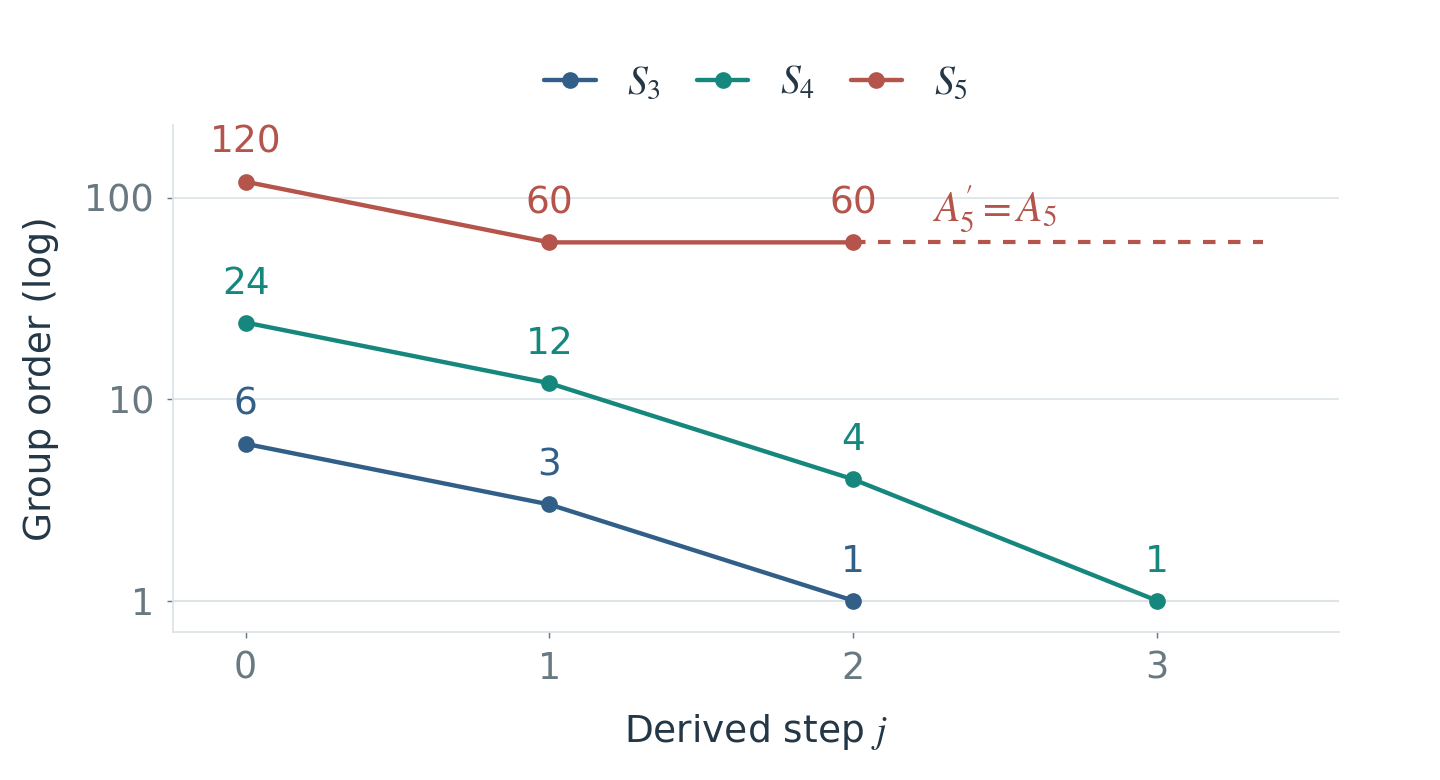

*Figure 7. At each integer step $j$, replace the current group by the subgroup generated by its commutators; a marker counts the remaining elements. The vertical scale is logarithmic, so equal vertical gaps represent equal ratios, not equal differences. The series for $S_3$ and $S_4$ reach order $1$ (identity only), while $S_5$ remains at the order-$60$ group $A_5$.*

## 13. The obstruction inside $S_5$

The key calculation is

$$
S_5'=A_5,\qquad A_5'=A_5.
\tag{48}
$$

The derived series never reaches the identity:

$$
\begin{gathered}
S_5\supset A_5=A_5'=\cdots,\\
120\longrightarrow60\longrightarrow60\longrightarrow\cdots.
\end{gathered}
\tag{49}
$$

Compare this with $S_3\to A_3\to\lbrace e\rbrace $. For the cubic, the first nonabelian group leaves a smaller abelian group that disappears at the next step. For $S_5$, the remaining $A_5$ produces itself again.

One concrete commutator shows how 3-cycles persist: the even permutations $g=(12)(34)$ and $h=(12)(35)$ satisfy $[g,h]=(345)$. The notation $(345)$ means $3\to4\to5\to3$, with $1,2$ fixed after the full composition. Relabeling this construction by even permutations gives every 3-cycle. Products of those 3-cycles give every even permutation, so they **generate** all of $A_5$. Thus the conclusion is stronger than “the maps do not commute”: the entire 60-element group remains after taking commutators.

A terminating derived series is necessary for any decomposition into abelian quotient stages. Since $A_5$ remains unchanged, no alternative choice of subgroup chain can remove the obstruction.


#### Why the 3-cycles force A5 to remain unchanged


Every commutator in $S_5$ is even: the signs of $g,h,g^{-1},h^{-1}$ multiply to $1$. Thus $S_5'\subseteq A_5$. Commutators of overlapping transpositions are 3-cycles, and conjugation supplies every 3-cycle.

To see why 3-cycles generate every even permutation, express one as an even number of transpositions and group them in pairs. Equal pairs cancel, overlapping pairs give 3-cycles, and disjoint pairs satisfy

$$
(ab)(cd)=(acb)(acd),
\tag{50}
$$

with rightmost-first composition. Thus $S_5'=A_5$.

For the derived subgroup of $A_5$ itself, choose

$$
\begin{gathered}
g=(12)(34),\\
h=(12)(35).
\end{gathered}
\tag{51}
$$

Both permutations are even. Direct composition gives

$$
[g,h]=(345).
\tag{52}
$$

Since $A_5'$ is normal, relabeling its permutations by an element of $A_5$ keeps them inside $A_5'$. In symbols, it contains $k(345)k^{-1}=(k(3)\ k(4)\ k(5))$ for every $k\in A_5$. These are the $A_5$-conjugates of $(345)$; “conjugate” here means the same cycle with consistently renamed labels.

To obtain any desired 3-cycle, first choose a permutation with the required three images. If it is odd, compose it on the right with $(12)$, the swap of the two unused original labels. This changes its parity without changing the three images. Equivalently, $(12)$ commutes with $(345)$, so the resulting conjugate is unchanged. Every 3-cycle is therefore obtained using an even relabeling.

Thus $A_5'$ contains every 3-cycle, hence the whole group they generate. Therefore $A_5'=A_5$. Merely finding one nontrivial commutator would not prove this: the conjugation and generation steps are essential.




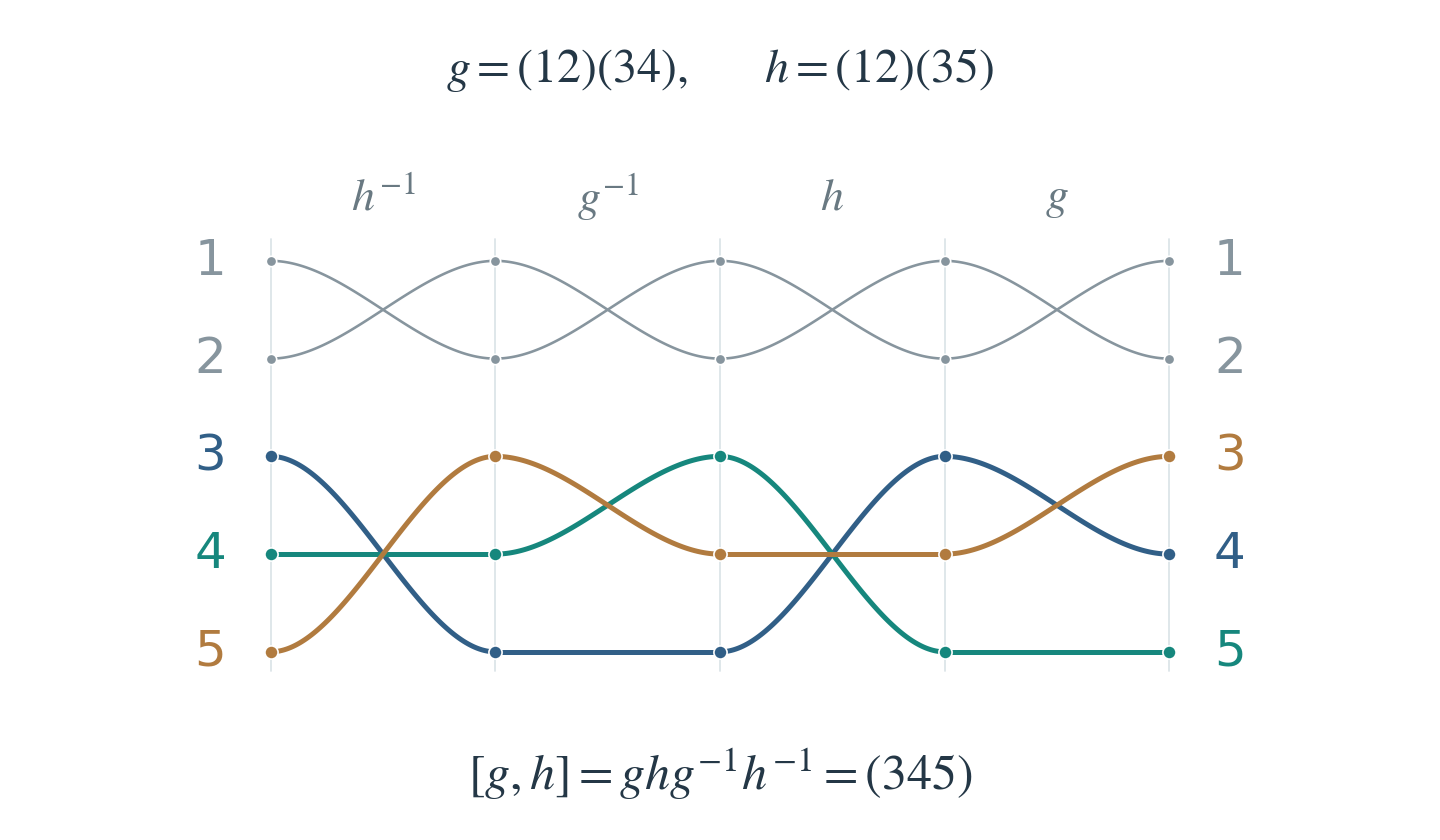

*Figure 8. Lines track the five labels through $h^{-1},g^{-1},h,g$, left to right on desktop and top to bottom on mobile. The gray labels $1,2$ return only after all four operations; the colored labels form the cycle $(345)$. Producing this cycle and all its conjugates gives $A_5'=A_5$.*

### Implementing the group calculation

A **generator** is an allowed building block; the **generated subgroup** includes identity and everything obtainable by repeatedly composing the generators and their inverses. For a single 3-cycle $r=(123)$, the generator list contains only $r$, but the generated subgroup is $\lbrace e,r,r^2\rbrace$: the third power returns to $e$. Adding the swap $(12)$ generates all six permutations in $S_3$.

A finite computation can verify the derived orders directly. At each stage, the commutators are building blocks for the next subgroup. Merely listing their individual values is insufficient: their products must be included too. **Closure** means continuing to add these products until no new permutation appears.


#### Python implementation: closure and the complete derived series


A permutation is represented by its zero-based images: `(1, 0, 2)` exchanges labels $0$ and $1$. Its entry at index `i` says where `i` goes; `(1, 2, 0)` therefore sends $0\to1\to2\to0$. Displayed cycle notation instead starts at $1$. The function `compose(p,q)` applies `q` first, then `p`.

In `group_closure`, `found` holds all permutations obtained so far and `pending` holds those whose products still need exploring. The generators and their inverses are applied until `pending` is empty. This is the same finite-search pattern used to find all vertices reachable from a starting vertex. `derived_subgroup` first collects the commutators and then runs that closure search.


In [2]:
from itertools import permutations

def compose(p, q):
    """Apply q first, then p."""
    return tuple(p[q[i]] for i in range(len(p)))

def inverse(p):
    result = [0] * len(p)
    for i, image in enumerate(p):
        result[image] = i
    return tuple(result)

def group_closure(generators, n):
    """Generate the subgroup, rather than just listing its generators."""
    identity = tuple(range(n))
    generators = set(map(tuple, generators))
    generators |= {inverse(g) for g in generators}
    found = {identity}
    pending = [identity]
    while pending:
        current = pending.pop()
        for generator in generators:
            candidate = compose(current, generator)
            if candidate not in found:
                found.add(candidate)
                pending.append(candidate)
    return found

def commutator(g, h):
    return compose(compose(compose(g, h), inverse(g)), inverse(h))

def derived_subgroup(group):
    # Products of commutators must be included, not just the commutators.
    group = set(group)
    n = len(next(iter(group)))
    generators = {commutator(g, h) for g in group for h in group}
    return group_closure(generators, n)

def derived_orders(group):
    group = set(group)
    orders = [len(group)]
    while len(group) > 1:
        next_group = derived_subgroup(group)
        orders.append(len(next_group))
        if next_group == group:  # A nontrivial fixed point is an obstruction.
            break
        group = next_group
    return orders

for n, expected in [(3, [6, 3, 1]), (4, [24, 12, 4, 1]),
                    (5, [120, 60, 60])]:
    actual = derived_orders(permutations(range(n)))
    assert actual == expected
    print(f"S_{n}: {actual}")


S_3: [6, 3, 1]
S_4: [24, 12, 4, 1]
S_5: [120, 60, 60]


The results are the exact orders $6,3,1$; $24,12,4,1$; and $120,60,60$. Enumeration verifies these finite groups, not Galois's criterion for arbitrary polynomials. The loop stops either at the identity or when the derived subgroup is unchanged.




**Derived-series workbench:** [Open the browser activity](https://pilkwangkim.github.io/posts/Galois-Theory-From-Scratch/#lab-galois-derived).


Compare $C_5$, $S_3$, $S_4$, $A_5$, and $S_5$. Before stepping, predict whether the chain will reach identity: $C_5$ is abelian, $S_3$ and $S_4$ are nonabelian but solvable, and $A_5$ and $S_5$ are nonsolvable. A repeated order means the subgroup itself is unchanged, because each next subgroup is contained in the previous one. Reaching order $1$ is success; remaining at order $60$ is not.

## 14. A specific quintic whose Galois group is $S_5$

The nonsolvability of $S_5$ is an obstruction only if an actual quintic has that Galois group. Such an equation is

$$
f(x)=x^5-5x+1.
\tag{53}
$$

Its coefficients are rational, yet its Galois group is the full $S_5$. Irreducibility and the number of nonreal roots establish this exactly; decimal approximations are not needed.

### 14.1 Irreducibility: a shift exposes Eisenstein's criterion

**Irreducible over $\mathbb Q$** means that a polynomial cannot be written as a product of two positive-degree polynomials with rational coefficients. For example, $x^2-2$ is irreducible over $\mathbb Q$, although it factors over $\mathbb R$ as $(x-\sqrt2)(x+\sqrt2)$. The choice of coefficient field is essential. The earlier quartic $(x^2-2)(x^2-3)$ is reducible over $\mathbb Q$, because its two displayed factors already have rational coefficients.

Checking that a quintic has no rational root would only exclude a linear factor; a quadratic times a cubic would still be possible. **Eisenstein's criterion** rules out all positive-degree factorizations at once. For an integer polynomial and a prime $p$, its conditions are: $p$ does not divide the leading coefficient, $p$ divides every other coefficient, and $p^2$ does not divide the constant coefficient. The conclusion is irreducibility over $\mathbb Q$.

The original $f$ does not visibly satisfy this test. Substitute $x-1$:

$$
\begin{aligned}
f(x-1)&=x^5-5x^4+10x^3\\
      &\quad-10x^2+5.
\end{aligned}
\tag{54}
$$

In descending powers, the coefficient list is $(1,-5,10,-10,0,5)$. The leading coefficient is $1$; every other coefficient is divisible by $5$, including $0$. The constant coefficient $5$ is not divisible by $25$. These are the conditions of **Eisenstein's criterion** at $5$, which imply that $f(x-1)$ is irreducible over $\mathbb Q$.

The substitution is reversible: a factorization of $f(x)$ would give one of $f(x-1)$ by replacing $x$ with $x-1$, and the reverse substitution is $x+1$. Thus $f$ itself is irreducible over $\mathbb Q$.


#### Why this coefficient test works: reduction modulo 5


Arithmetic **modulo $5$** keeps only the remainder after division by $5$, chosen from $0,1,2,3,4$. For example, $7$ becomes $2$, $-1$ becomes $4$, and $-5$ becomes $0$; $3+4$ is therefore $2$, while $2\cdot3$ is $1$. We write $7\equiv2\pmod5$ to say that the remainders agree. These five remainders form the finite field $\mathbb F_5$: division by any nonzero remainder is possible, since $1,2,3,4$ have inverses $1,3,2,4$, respectively.

Reducing an integer polynomial means replacing each coefficient by its remainder. Addition and multiplication still respect polynomial identities: if $A B=F$ before reduction, the reduced polynomials still satisfy that identity. For (54), all terms except $x^5$ disappear. The bar over a polynomial below denotes its coefficient-by-coefficient reduction, not complex conjugation.

Suppose that this monic polynomial—one with leading coefficient $1$—had a rational factorization. **Gauss's lemma**, justified in the separate box below, would give monic integer factors $A(x),B(x)$ of positive degree. Their leading coefficients remain $1$ after reduction, so their degrees do not drop. Reducing the factorization gives

$$
\overline A(x)\,\overline B(x)=x^5.
\tag{55}
$$

Both reduced factors must be positive powers of $x$. One elementary way to see this is to compare constant coefficients: if a product is divisible by $x$, at least one factor has constant coefficient $0$ and is itself divisible by $x$. Cancel that $x$ and repeat until the product is $1$. All five copies of $x$ have been distributed between the two monic factors, leaving no other factors. Since their degrees are positive, each has at least one copy of $x$.

Thus both integer constant coefficients are divisible by $5$. Their product would be divisible by $25$, contradicting the constant coefficient $5$.

The argument tests a hypothetical factorization over $\mathbb Q$; it does not replace the original problem by one over $\mathbb F_5$. Any integer factorization would still be an identity after reduction, and (55) makes such a factorization impossible.




#### Why Gauss's lemma permits integer factors


Rational factors may contain denominators even when their product has integer coefficients: $(x/2+1/2)(2x-2)=x^2-1$. Factoring out the numerical multipliers gives $(1/2)(x+1)\cdot2(x-1)$, and the multipliers cancel. Gauss's lemma says that a primitive integer polynomial always allows this cancellation, leaving integer polynomial factors.

The **content** of an integer polynomial is the positive greatest common divisor of its coefficients. For example, $2x+2$ has content $2$, while $x+1$ and $2x+1$ each have content $1$. A polynomial of content $1$ is called **primitive**; this use of “primitive” is unrelated to a primitive root of unity. Dividing by the content separates an integer polynomial into a numerical multiplier and a primitive polynomial.

A product of primitive integer polynomials is primitive. Otherwise some prime $p$ would divide every coefficient of the product. Reduction modulo $p$ would give a zero product of two nonzero polynomials over $\mathbb F_p$. That is impossible: the leading coefficient of their product is the product of two nonzero leading coefficients and is nonzero in this field. The fact that $p$ is prime ensures this; nonprime moduli need not give a field.

Now clear denominators in any rational factorization of a primitive integer polynomial $F$. Extract the contents of the resulting integer factors to write $F=r A B$, where $A,B$ are primitive integer polynomials and $r$ is rational. The product $A B$ is primitive. Write $r=u/v$ in lowest terms with $v>0$. Since every coefficient of $F$ is an integer, $v$ divides every coefficient of $A B$, forcing $v=1$. Primitivity of $F$ then forces $\lvert u\rvert=1$. Thus $F=\pm A B$ has integer factors. If $F$ is monic, their integer leading coefficients multiply to $1$, so signs can be adjusted to make both factors monic. This is the form of Gauss's lemma used in (55).



### 14.2 Three real roots and one nonreal pair

The number of real roots determines what complex conjugation does to the five labels. It is enough to locate the turning points, where the function switches between increasing and decreasing; exact expressions for the roots are unnecessary. The derivative is

$$
f'(x)=5(x^4-1).
\tag{56}
$$

It is positive for $x<-1$, negative for $-1<x<1$, and positive for $x>1$. Thus the polynomial increases, then decreases, then increases. Its turning-point values are

$$
f(-1)=5,\qquad f(1)=-3.
\tag{57}
$$

Since the leading term is $x^5$, the function tends to $-\infty$ on the far left and $+\infty$ on the far right. It is continuous and moves strictly in one direction on each of these three intervals. It therefore crosses zero exactly once in each of $(-\infty,-1)$, $(-1,1)$, and $(1,\infty)$.

Complex conjugation sends $a+bi$ to $a-bi$: it exchanges $2+3i$ and $2-3i$, for example, but fixes every real number. Since $f$ has real coefficients, $f(\overline z)=\overline{f(z)}$. A nonreal root therefore comes with its conjugate.

Separability excludes repeated roots, so the remaining two roots are exactly one nonreal conjugate pair. Conjugation fixes the three real roots and exchanges just this pair. It preserves addition and multiplication, fixes $\mathbb Q$, and maps the splitting field onto itself. It is therefore a $\mathbb Q$-automorphism whose root permutation is a single transposition. No label choices are needed to find it: label the two nonreal roots $4,5$, for example, and this automorphism becomes $(45)$.


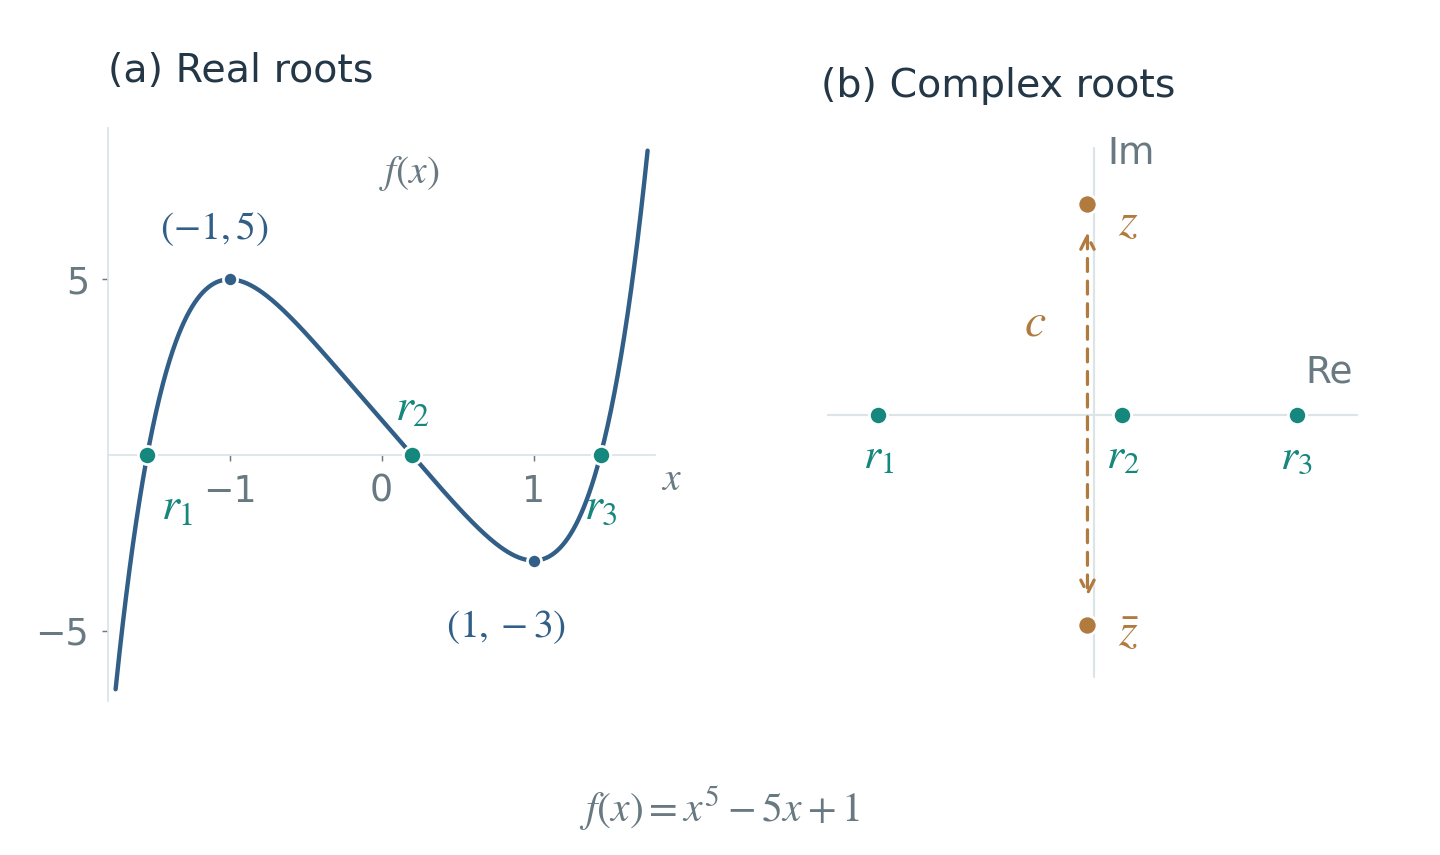

*Figure 9. The real curve shows three crossings and the critical values $f(-1)=5$, $f(1)=-3$. The complex plane locates all five roots: conjugation fixes the three real roots and exchanges only $z,\bar z$, giving one transposition. The derivative argument establishes the exact root count.*

### 14.3 Transitivity and a transposition determine S₅


The **orbit** of a root is the set of roots reachable from it by allowed automorphisms. In the quartic $(x^2-2)(x^2-3)$ from section 6, the orbit of $\sqrt2$ is $\lbrace \sqrt2,-\sqrt2\rbrace $, not all four roots: an automorphism cannot turn a number whose square is $2$ into one whose square is $3$. The other orbit is $\lbrace \sqrt3,-\sqrt3\rbrace $.

An action is **transitive** when there is only one orbit: any root can be sent to any other. An irreducible polynomial over $\mathbb Q$ has this property. A smaller orbit would supply a factor over $\mathbb Q$, just as the two orbits in the quartic supply the factors $x^2-2$ and $x^2-3$.


#### Why an orbit gives a factor over the base field


Let $L$ be the splitting field of an irreducible polynomial over $F$, where the characteristic is $0$, and let $G=\operatorname{Gal}(L/F)$. For an orbit $O$, form the polynomial $q_O(x)=\prod_{\beta\in O}(x-\beta)$.

Every element of $G$ permutes $O$, so it fixes the coefficients of $q_O$: reordering its factors does not change their product. The fixed-field theorem from section 7 says $L^G=F$. Thus those coefficients lie in $F$, not merely in $L$.

The polynomial $q_O$ has positive degree and divides the original polynomial in $L[x]$. Because both polynomials have coefficients in $F$, division by the monic polynomial $q_O$ gives the same zero remainder in $F[x]$. Irreducibility rules out a proper nonconstant factor. Hence $O$ contains all the roots, which is transitivity.



Our group $G\le S_5$ is therefore transitive and contains a transposition. Neither fact alone would imply $G=S_5$: a five-cycle by itself moves any label to any other but generates only five permutations, while one swap alone generates only two. Together, on a prime number of labels, they force the full symmetric group.

To see why, suppose the known swap is $(45)$. If $g$ sends $4$ to $1$ and $5$ to $3$, then $g(45)g^{-1}=(13)$ is another available swap. Draw one point, or **vertex**, for each root label. Join two vertices by a line, or **edge**, whenever their swap is obtained this way. This is a graph of available **swaps between labels**, not a graph whose vertices are group elements.

A **path** follows consecutive edges. A **connected component** contains all vertices reachable from any one of its members along paths. A graph is **connected** when it has just one such component.

An element of $G$ consistently renames all vertices and edges, so it takes an entire connected component onto another component. Transitivity lets us send a vertex in any component to a vertex in any other; all components must therefore have the same size. Five vertices can form either one component of size $5$ or five components of size $1$, because $5$ is prime. The known edge rules out the latter. For a composite number such as $6$, equal components of size $2$ or $3$ would also be possible; the prime-degree assumption is doing real work.

In a connected graph, edge swaps can exchange even nonadjacent vertices. For a path $1$–$2$–$3$, the product $(12)(23)(12)=(13)$ exchanges the endpoints and leaves the middle vertex fixed; as before, products act rightmost first. Repeating this along paths gives every transposition, and transpositions generate every permutation.


#### The conjugate-edge graph argument in full


Let the known transposition be $(a\,b)$. Make a graph with the five root labels as vertices. For each $g\in G$, draw an edge

$$
\{g(a),g(b)\}.
\tag{58}
$$

The swap along this edge is $g(a\,b)g^{-1}$, so it belongs to $G$. Applying $h\in G$ sends the edge indexed by $g$ to the edge indexed by $hg$. It therefore preserves the graph and takes each connected component bijectively onto another component. Transitivity lets us send a vertex in any component to a vertex in any other, so all components have the same size. That size divides $5$. An edge exists, so components cannot have size $1$; since $5$ is prime, the graph is connected.

Edge transpositions in a connected graph generate every permutation. Suppose a swap $(u\,v)$ has already been constructed along a path and the next edge is $(v\,w)$, with distinct $u,v,w$. Then $(u\,v)(v\,w)(u\,v)=(u\,w)$ extends the constructed swap to the next vertex. Starting with the first edge, this gives a swap between any two endpoints joined by a simple path. Arbitrary transpositions generate $S_5$, so $G$ contains $S_5$ and equality follows. The primality of $5$ is essential.



Combining the three steps,

$$
\operatorname{Gal}(f/\mathbb Q)=S_5.
\tag{59}
$$

Here $\operatorname{Gal}(f/\mathbb Q)$ means the Galois group of the splitting field of $f$ over $\mathbb Q$. [Milne, §4, prime-degree criterion](https://www.jmilne.org/math/CourseNotes/FT.pdf)


## 15. The conclusion: no universal radical formula

The chain for the concrete equation is

$$
\begin{gathered}
f(x)=x^5-5x+1,\\
\text{irreducible,}\\
\text{exactly two nonreal roots}\\
\Longrightarrow
\operatorname{Gal}(f/\mathbb Q)=S_5,\\
S_5'=A_5,\qquad A_5'=A_5,\\
\Longrightarrow
f\text{ not solvable}\\
\text{by radicals}.
\end{gathered}
\tag{60}
$$

If a radical recipe worked for **every** quintic with rational coefficients, it would work for this one. It cannot. Therefore no universal quintic radical formula exists.

The obstruction does not disappear by allowing complex intermediate radicals; they were allowed from the definition. Nor does using more nested radicals help. Any finite number still yields a radical tower, and the solvability argument applies.


#### The stronger conclusion: not even one root has a radical expression


For this irreducible polynomial, even one root cannot belong to a radical extension of $\mathbb Q$. If one did, the normal-closure construction from section 10 would place all its conjugates in a Galois extension with solvable group. Its minimal polynomial is $f$, so all five roots would lie there, contradicting (59) and (40).

Irreducibility is what makes the argument about one root an argument about all five: its minimal polynomial is the entire quintic, not a smaller factor.



Degree five is not a universal ban. For example,

$$
\begin{gathered}
x^5-2=0\\
\Longrightarrow
x_k=\sqrt[5]2\,\zeta_5^k,\\
k=0,\ldots,4.
\end{gathered}
\tag{61}
$$

These are radical expressions: $\zeta_5$ is a primitive fifth root of $1$, one of the allowed fifth-root choices. “Primitive” means that $1,\zeta_5,\zeta_5^2,\zeta_5^3,\zeta_5^4$ are all distinct before the fifth power returns to $1$. Over $\mathbb Q$, the splitting-field Galois group has order $20$ and is solvable; it is not simply $C_5$. After adjoining $\zeta_5$, the remaining degree-five stage is cyclic.


#### Why the solvable quintic has group order 20


The field obtained by adjoining a root of unity is called a **cyclotomic field**; here it is $\mathbb Q(\zeta_5)$. The nonidentity fifth roots satisfy $x^4+x^3+x^2+x+1=0$, because $(x-1)(x^4+x^3+x^2+x+1)=x^5-1$. Substituting $x+1$ into the quartic gives $x^4+5x^3+10x^2+10x+5$, which is Eisenstein at $5$. The quartic is therefore the minimal polynomial and the field degree is $4$.

Its automorphisms send $\zeta_5$ to $\zeta_5^u$ for $u=1,2,3,4$. Composing these maps multiplies the exponents modulo $5$. Powers of $2$ give the sequence $1,2,4,3,1$ modulo $5$, so the map $\zeta_5\mapsto\zeta_5^2$ generates all four automorphisms: the group is $C_4$.

Let $L=\mathbb Q(\sqrt[5]2,\zeta_5)$. Its degree is at most $20$ by adjoining a fifth root after the degree-four extension. It is divisible by both $4$ and $5$, because it contains the degree-four cyclotomic field and the degree-five field $\mathbb Q(\sqrt[5]2)$, whose defining polynomial is Eisenstein at $2$. Hence $[L:\mathbb Q]=20$.

The subgroup fixing $\zeta_5$ has order $20/4=5$. It sends $\sqrt[5]2$ to $\sqrt[5]2\,\zeta_5^k$, and repeated application adds exponents modulo $5$, giving $C_5$. The quotient records the four possible changes of $\zeta_5$ and is $C_4$. Both are abelian, so the full group is solvable. Counting only the visible fifth-root choices misses the root-of-unity symmetries.



## 16. Numerical roots remain accessible

The three real roots of (53) lie in rational sign-changing brackets $[-3,-1]$, $[-1,1]$, and $[1,3]$. **Bisection** repeatedly halves a bracket while retaining a sign change. Continuity guarantees that the bracket still contains a root.

For the middle bracket, $f(-1)=5$ and $f(1)=-3$. Its midpoint is $0$, where $f(0)=1$, so keep $[0,1]$. The next midpoint is $1/2$, where $f(1/2)=-47/32$, so keep $[0,1/2]$. Each decision narrows the root's location; it does not turn the root into a radical expression.

There are two different uses of **exact** here. The root can be specified exactly as “the unique zero of $x^5-5x+1$ in $[0,1/2]$,” and rational arithmetic can certify arbitrarily small intervals containing it. Neither is a finite radical expression. After any finite number of bisection steps, the output is generally a rational approximation together with an error bound, not the root itself.


#### Exact-rational implementation and a guaranteed error bound


After $k$ steps from an initial interval of width $W$,

$$
\begin{gathered}
W_k=\frac{W}{2^k},\\
\lvert x_{\mathrm{mid}}-\alpha\rvert
\le\frac{W}{2^{k+1}}.
\end{gathered}
\tag{62}
$$

For these intervals the root is unique because the function moves strictly in one direction. The code uses exact rational endpoints rather than finite-precision floating-point approximations. Its sign decisions and interval-width bound therefore do not depend on roundoff—the error introduced by storing numbers with only a fixed number of digits.

The printed error bound applies to the displayed 12-decimal value, not just the exact midpoint. It adds the display's rounding error to the interval half-width, then rounds the bound upward in units of $10^{-15}$.


In [3]:
from fractions import Fraction
from math import ceil

def quintic(x):
    return x**5 - 5*x + 1

def bisect_exact(f, left, right, steps=50):
    left, right = Fraction(left), Fraction(right)
    if left >= right or steps < 0:
        raise ValueError("Use an increasing interval and nonnegative steps")
    fl, fr = f(left), f(right)
    if fl == 0:
        return left, left
    if fr == 0:
        return right, right
    if fl * fr > 0:
        raise ValueError("The endpoints must have opposite signs")
    for _ in range(steps):
        midpoint = (left + right) / 2
        fm = f(midpoint)
        if fm == 0:
            return midpoint, midpoint
        if fl * fm < 0:
            right = midpoint
        else:
            left, fl = midpoint, fm
    return left, right

for bracket in [(-3, -1), (-1, 1), (1, 3)]:
    left, right = bisect_exact(quintic, *bracket)
    midpoint = (left + right) / 2
    assert right - left <= Fraction(2, 2**50)
    displayed = f"{float(midpoint):.12f}"
    error_bound = abs(Fraction(displayed) - midpoint) + (right - left) / 2
    # Both terms are exact; rounding upward keeps the printed bound conservative.
    bound_units = ceil(error_bound * 10**15)
    print(f"root ≈ {displayed}; error ≤ {bound_units}e-15")


root ≈ -1.541651684105; error ≤ 476e-15
root ≈ 0.200064102630; error ≤ 26e-15
root ≈ 1.440500397342; error ≤ 442e-15


The approximations are about $-1.541651684105$, $0.200064102630$, and $1.440500397342$. The other two roots are approximately $-0.049456407934\pm1.499441367239\,i$. These decimals describe locations; the exact arguments in section 14 established the group.




**Numerical roots and radical formulas:** [Open the browser activity](https://pilkwangkim.github.io/posts/Galois-Theory-From-Scratch/#lab-galois-quintic).


Before each bisection step, use the midpoint's sign to predict which half will remain, then check the interval width. Switch to $x^5-2$: the same method approximates both a radical-solvable and a radical-nonsolvable polynomial. Numerical convergence does not test radical solvability. A small residual $\lvert f(x)\rvert$ measures how close the function value is to zero; it is not by itself a bound on the error in $x$. Here the sign-changing interval supplies that guarantee.


#### Optional SymPy check: exact structure and numerical output


The core Python examples require only the standard library. The following independent check additionally requires SymPy. It computes the Galois group symbolically and approximates the roots numerically; these are separate operations. The API was checked with SymPy 1.14.0. [SymPy number-field documentation](https://docs.sympy.org/latest/modules/polys/numberfields.html)


In [4]:
import sympy as sp
from sympy.polys.numberfields import galois_group

x = sp.Symbol("x")
f = x**5 - 5*x + 1
assert sp.expand(f.subs(x, x - 1)) == x**5 - 5*x**4 + 10*x**3 - 10*x**2 + 5
assert sp.Poly(f, x).is_irreducible
group, contained_in_alternating = galois_group(f, x)
assert group.order() == 120 and not group.is_solvable
assert not contained_in_alternating
print("Galois-group order:", group.order())
print("Numerical roots:", sp.nroots(f))


Galois-group order: 120
Numerical roots: [-1.54165168410452, 0.200064102629975, 1.44050039734156, -0.0494564079335054 - 1.49944136723915*I, -0.0494564079335054 + 1.49944136723915*I]


The library's permutation multiplication convention need not match the explicit `compose` function above. Group order and solvability are invariant; when comparing individual permutations, translate the convention rather than mixing products.



## 17. Exercises: distinguish the exact obstruction

The questions use only the distinctions already established: a finite formula versus successive approximations; preserving linear combinations versus preserving products; and shrinking a derived series versus merely being nonabelian. For the field–subgroup question, recall that fixing more numbers permits fewer automorphisms. No additional theorem or symbolic-algebra package is needed.


#### Printable quiz inputs



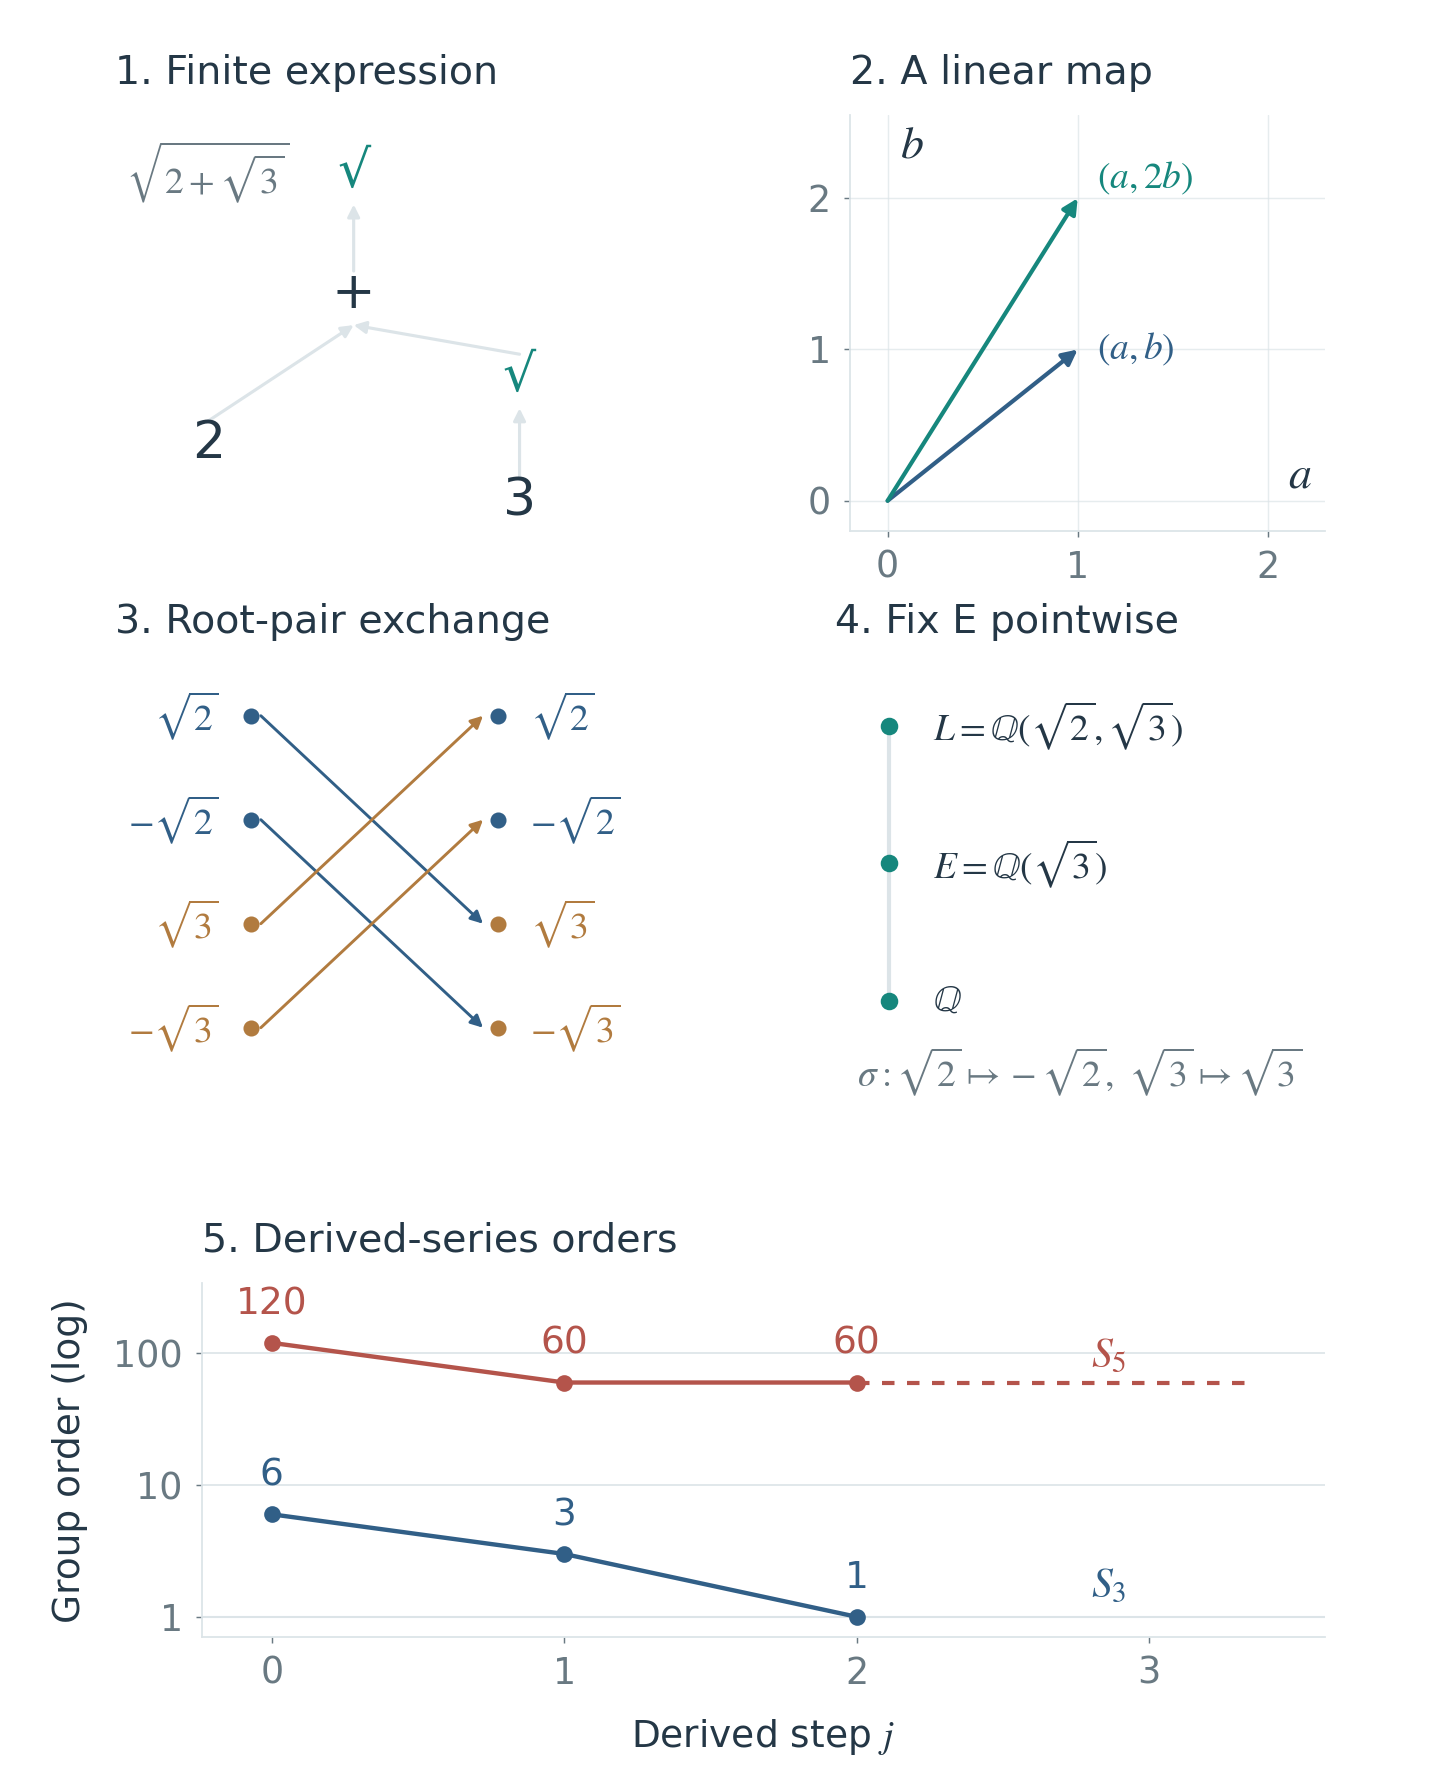

*Figure 10. Inputs for the five interactive questions. Panel 2 uses rational coordinates in the basis $(1,\sqrt2)$; panel 3 keeps $2,3$ fixed; panel 4 specifies $\sigma$ and the field $E$. The final panel gives derived-subgroup orders.*




**Five illustrated questions:** [Open the browser activity](https://pilkwangkim.github.io/posts/Galois-Theory-From-Scratch/#lab-galois-quiz).


#### 1. What counts as a radical formula?

For an irrational root of a rational-coefficient polynomial, which step is permitted when building an exact radical expression?

**Diagram input:**

- `coefficients`
- `+ − × ÷`
- `m-th roots`
- `finite expression`

1. Take a cube root of an earlier expression.
2. Use “the smallest real root” as a new operation.
3. Treat a 12-decimal bisection approximation as the exact root.

**Hint:** An exact expression must equal the target root, not merely approximate it.

**Answer: 1.** Radicals and field operations are exactly the allowed finite operations.

**Reasoning for every choice:**

- **1.** Radicals and field operations are exactly the allowed finite operations.
- **2.** An implicit root selector names a root but does not express it using the allowed operations.
- **3.** The finite decimal is rational and is itself an allowed constant, but it is not equal to the target irrational root. An approximation is not an exact formula for that root.


#### 2. Linear map or field automorphism?

T is Q-linear and invertible. Is it a Q-automorphism of Q(√2)?

**Diagram input:**

- `basis: (1, √2)`
- `T(a + b√2) = a + 2b√2`
- `T(√2)²  ?  T(2)`

1. Yes: invertible linear maps preserve multiplication.
2. No: T(√2)² = 8 but T(2) = 2.
3. No: no nonidentity automorphism is possible.

**Hint:** Apply T to the relation (√2)² = 2.

**Answer: 2.** The multiplication relation fails, so T is not a field automorphism.

**Reasoning for every choice:**

- **1.** Linearity preserves addition and rational scaling, not arbitrary products.
- **2.** The multiplication relation fails, so T is not a field automorphism.
- **3.** Conjugation a+b√2 ↦ a−b√2 is a nonidentity automorphism.


#### 3. Can two square-root pairs be exchanged?

The four roots of (x²−2)(x²−3) are permuted bijectively as shown. Does this extend to a Q-automorphism?

**Diagram input:**

- `√2 ↔ √3`
- `−√2 ↔ −√3`
- `2 and 3 stay fixed`

1. Yes: every root is still a root of the same quartic.
2. Yes: the permutation has an inverse.
3. No: the equation α² = 2 would become 3 = 2.

**Hint:** A Q-automorphism must preserve every rational polynomial relation, not just the product polynomial.

**Answer: 3.** Rational constants are fixed, so √2 cannot be sent to an element whose square is 3.

**Reasoning for every choice:**

- **1.** Remaining in the root set is necessary but not sufficient.
- **2.** An inverse makes this a permutation, but does not ensure that it respects multiplication.
- **3.** Rational constants are fixed, so √2 cannot be sent to an element whose square is 3.


#### 4. Fix more numbers, allow fewer symmetries

Which subgroup fixes every element of E=Q(√3)?

**Diagram input:**

- `L = Q(√2, √3)`
- `σ: √2 ↦ −√2, √3 ↦ √3`
- `E = Q(√3)`

1. {e, σ}
2. The full four-element group.
3. Only e, because √3 is irrational.

**Hint:** The image of √2 is unrestricted by fixing √3.

**Answer: 1.** Both e and σ fix √3 and every rational combination of it.

**Reasoning for every choice:**

- **1.** Both e and σ fix √3 and every rational combination of it.
- **2.** τ flips √3, so the full group does not fix E pointwise.
- **3.** Fixing √3 still allows √2 to change sign.


#### 5. Nonabelian does not mean nonsolvable

Which conclusion follows from these derived-series orders?

**Diagram input:**

- `S₃: 6 → 3 → 1`
- `S₅: 120 → 60 → 60`
- `orders of derived subgroups`

1. Neither group is solvable because both are nonabelian.
2. S₃ is solvable; S₅ is not.
3. S₅ is solvable because its order decreases once.

**Hint:** Solvability requires reaching the identity group, not just shrinking once.

**Answer: 2.** S₃ reaches order 1. S₅ reaches A₅, whose 60 elements also form its derived subgroup, so the next step gives A₅ again.

**Reasoning for every choice:**

- **1.** A nonabelian group may still have a derived series ending at the identity.
- **2.** S₃ reaches order 1. S₅ reaches A₅, whose 60 elements also form its derived subgroup, so the next step gives A₅ again.
- **3.** The remaining A₅ has order 60 and equals its own derived subgroup.


The five questions test finite radicals versus approximation, linearity versus multiplicativity, allowed root permutations, reversed field–subgroup inclusion, and nonabelian versus nonsolvable groups. Each option has its own explanation. Previous/Next preserves choices; Reset starts over.

### Coding exercise: generators are not the generated group

Implement `generated_solvable(generators, n)`. Its inputs are valid zero-based permutations of $n$ labels. First generate the subgroup, then repeatedly generate its derived subgroup. Return `True` exactly when the series reaches the identity; return `False` if a nontrivial subgroup repeats. Do not classify the group by its initial size.

For a concrete input, `generated_solvable([(1, 0, 2), (1, 2, 0)], 3)` must return `True`. Here `n=3` counts the labels `0, 1, 2`; it is **not** the group order. The first tuple exchanges labels `0` and `1`, while the second sends `0 → 1 → 2 → 0`. Their closure contains all six elements of $S_3$. The derived-subgroup orders are $6\to3\to1$, so the Boolean answer is `True` even though the group is nonabelian.

By contrast, the $S_5$ test below has only two input generators but a closure of order $120$. Its derived-subgroup orders are $120\to60\to60$: the nonidentity fixed point requires `False`. The function returns this Boolean, not the order trace.

The functions `group_closure` and `derived_subgroup` from section 13 are available; their implementations need not be rewritten. `group` is a Python set of permutation tuples. Thus `len(group)` counts its elements, and `next_group == group` compares the actual sets, not just their sizes. For empty input generators, closure still contains identity, so the loop is skipped and the answer is `True`.

The starter omits two decisions: which helper computes the next subgroup, and what to return if that subgroup equals the current nonidentity group. It is an intentionally unfinished exercise: calling it before filling the TODOs raises `NotImplementedError`.


In [5]:
def generated_solvable(generators, n):
    """Complete the two TODOs; input permutations are assumed valid."""
    group = group_closure(generators, n)
    while len(group) > 1:
        # TODO 1: compute the subgroup generated by all commutators.
        next_group = None
        if next_group is None:
            raise NotImplementedError("Replace TODO 1 with a derived subgroup")
        # TODO 2: what does equality imply when len(group) > 1?
        if next_group == group:
            raise NotImplementedError("Return the correct Boolean at a fixed point")
        group = next_group
    return True


The cases below include nonabelian groups with opposite answers. Their generators are explicit, so no group-theory library is needed.


#### Executable tests and reference solution


In [6]:
def reference_generated_solvable(generators, n):
    group = group_closure(generators, n)
    while len(group) > 1:
        next_group = derived_subgroup(group)
        if next_group == group:
            return False
        group = next_group
    return True

SOLVABILITY_CASES = [
    ("identity", [], 5, True),
    ("C5", [(1, 2, 3, 4, 0)], 5, True),
    ("V4", [(1, 0, 3, 2), (2, 3, 0, 1)], 4, True),
    ("S3", [(1, 0, 2), (1, 2, 0)], 3, True),
    ("S4", [(1, 0, 2, 3), (1, 2, 3, 0)], 4, True),
    ("A5", [(1, 2, 0, 3, 4), (1, 2, 3, 4, 0)], 5, False),
    ("S5", [(1, 0, 2, 3, 4), (1, 2, 3, 4, 0)], 5, False),
]

def test_solvability(candidate):
    for name, generators, n, expected in SOLVABILITY_CASES:
        actual = candidate(generators, n)
        assert actual is expected, (name, actual, expected)
    return len(SOLVABILITY_CASES)

assert test_solvability(reference_generated_solvable) == 7
print("Reference solution: 7/7 cases")
# After completing the starter, run: test_solvability(generated_solvable)


Reference solution: 7/7 cases


A derived subgroup is contained in the current group. If it is a **proper subgroup**, meaning strictly smaller, it has fewer elements; otherwise the subgroup has stabilized. Its order is a positive integer, so the loop either reaches order $1$ or detects a nontrivial fixed point.

The tests check seven specific groups. The proof that the procedure decides solvability follows from the definition and descending-chain argument, not merely from passing those cases.



## 18. What the quintic impossibility actually says

A field extension adds numbers while preserving arithmetic. Its vector-space dimension counts the independent coordinates needed to describe them. A Galois group records root exchanges compatible with all relations over the base field; an arbitrary permutation need not respect those relations.

Radicals can resolve abelian symmetry in successive stages. For degrees at most four, the symmetric groups—and all their subgroups—admit such a resolution. In $S_5$, commutators leave $A_5$, and commutators inside $A_5$ produce $A_5$ again.

The quintic $x^5-5x+1$ realizes that obstruction. Its roots are well-defined algebraic numbers and can be approximated to any chosen accuracy. What cannot exist is a finite expression for them using only rational starting values, arithmetic, and radicals.

## References

- [J. S. Milne, *Fields and Galois Theory*](https://www.jmilne.org/math/CourseNotes/FT.pdf): extension degrees, finite Galois correspondence, solvability criterion, and the prime-degree root-count criterion.
- [Keith Conrad, *Simple Radical Extensions*](https://kconrad.math.uconn.edu/blurbs/galoistheory/simpleradical.pdf): degrees of simple radical extensions and the choice of a radical root.
- [Romyar Sharifi, *Abstract Algebra*, Chapter 10](https://www.math.ucla.edu/~sharifi/notes/algebra-ch10.html): extensions by radicals and the solvability theorem.
- [John Beachy, *Galois Theory*](https://faculty.niu.edu/math_beachy/aaol/galois.shtml): field-theoretic interpretation of solving polynomial equations.
- [SymPy, Number Fields](https://docs.sympy.org/latest/modules/polys/numberfields.html): the optional exact Galois-group computation.
